In [4]:
# ============================================================
# CELL 1 — Install dependencies
# ============================================================
#!pip install shap imbalanced-learn xgboost lightgbm catboost statsmodels -q

In [5]:
# ============================================================
# CELL 2 — Imports
# ============================================================
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import seaborn as sns
from scipy.stats import mannwhitneyu
from statsmodels.stats.contingency_tables import mcnemar

from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                     cross_validate, RandomizedSearchCV)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, GradientBoostingClassifier,
                               StackingClassifier)
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                              f1_score, roc_auc_score, matthews_corrcoef,
                              confusion_matrix, ConfusionMatrixDisplay,
                              brier_score_loss, roc_curve, auc)
from imblearn.over_sampling import SMOTE
import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import shap

warnings.filterwarnings('ignore')
os.makedirs('outputs', exist_ok=True)

# Consistent plot style
plt.rcParams.update({
    'figure.dpi': 150,
    'font.family': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
})
PALETTE = {0: '#4C9BE8', 1: '#E8704C'}

print("✓ All imports successful")

✓ All imports successful


In [6]:
# ============================================================
# CELL 3 — Load data & drop PatientID
# ============================================================
df = pd.read_csv('/Users/abdullahalrakin/Desktop/alzheimer paper/alzheimers_disease_data.csv')
df = df.drop(columns=['PatientID', 'DoctorInCharge'], errors='ignore')
print(f"Dataset shape: {df.shape}")
print(f"Target distribution:\n{df['Diagnosis'].value_counts()}")
print(f"Imbalance ratio: {df['Diagnosis'].value_counts().max() / df['Diagnosis'].value_counts().min():.2f}:1")
df.head()



Dataset shape: (2149, 33)
Target distribution:
0    1389
1     760
Name: Diagnosis, dtype: int64
Imbalance ratio: 1.83:1


,Age,Gender,Ethnicity,EducationLevel,BMI,Smoking,AlcoholConsumption,PhysicalActivity,DietQuality,SleepQuality,...,FunctionalAssessment,MemoryComplaints,BehavioralProblems,ADL,Confusion,Disorientation,PersonalityChanges,DifficultyCompletingTasks,Forgetfulness,Diagnosis
0,73,0,0,2,22.927749,0,13.297218,6.327112,1.347214,9.025679,...,6.518877,0,0,1.725883,0,0,0,1,0,0
1,89,0,0,0,26.827681,0,4.542524,7.619885,0.518767,7.151293,...,7.118696,0,0,2.592424,0,0,0,0,1,0
2,73,0,3,1,17.795882,0,19.555085,7.844988,1.826335,9.673574,...,5.895077,0,0,7.119548,0,1,0,1,0,0
3,74,1,0,1,33.800817,1,12.209266,8.428001,7.435604,8.392554,...,8.965106,0,1,6.481226,0,0,0,0,0,0
4,89,0,0,0,20.716974,0,18.454356,6.310461,0.795498,5.597238,...,6.045039,0,0,0.014691,0,0,1,1,0,0


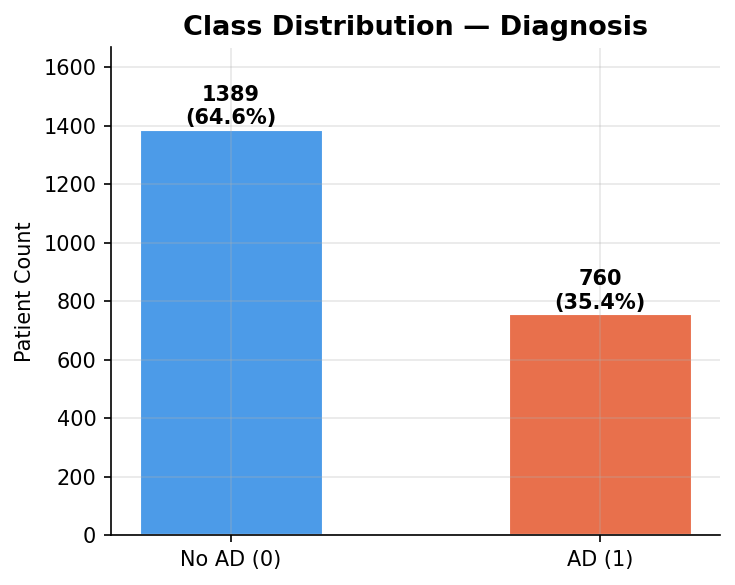

In [7]:
# ============================================================
# CELL 4 — EDA: Class distribution
# ============================================================
counts = df['Diagnosis'].value_counts()
fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(['No AD (0)', 'AD (1)'], counts.values,
              color=['#4C9BE8', '#E8704C'], edgecolor='white', linewidth=1.5, width=0.5)
for bar, val in zip(bars, counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, val + 15,
            f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=10, fontweight='bold')
ax.set_title('Class Distribution — Diagnosis', fontweight='bold', fontsize=13)
ax.set_ylabel('Patient Count')
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig('outputs/01_class_distribution.png', dpi=150, bbox_inches='tight')
plt.show()



In [8]:
# ============================================================
# CELL 5 — EDA: Univariate statistics
# ============================================================
numeric_cols = df.select_dtypes(include=np.number).columns.drop('Diagnosis').tolist()
stats = df[numeric_cols].agg(['mean', 'std', 'median', 'skew']).T
stats['Q25'] = df[numeric_cols].quantile(0.25)
stats['Q75'] = df[numeric_cols].quantile(0.75)
stats['IQR'] = stats['Q75'] - stats['Q25']
stats['HighSkew'] = stats['skew'].abs() > 1
stats = stats.round(3)
print("Univariate Statistics:")
print(stats)
print(f"\nHigh-skew features (|skew|>1): {stats[stats['HighSkew']].index.tolist()}")



Univariate Statistics:
                              mean      std   median   skew      Q25      Q75  \
Age                         74.909    8.990   75.000  0.046   67.000   83.000   
Gender                       0.506    0.500    1.000 -0.025    0.000    1.000   
Ethnicity                    0.698    0.996    0.000  1.230    0.000    1.000   
EducationLevel               1.287    0.905    1.000  0.209    1.000    2.000   
BMI                         27.656    7.217   27.824 -0.027   21.611   33.870   
Smoking                      0.289    0.453    0.000  0.934    0.000    1.000   
AlcoholConsumption          10.039    5.758    9.934  0.018    5.140   15.158   
PhysicalActivity             4.920    2.857    4.766  0.045    2.571    7.428   
DietQuality                  4.993    2.909    5.076 -0.012    2.458    7.559   
SleepQuality                 7.051    1.764    7.116 -0.070    5.483    8.563   
FamilyHistoryAlzheimers      0.252    0.434    0.000  1.142    0.000    1.000   
Cardi

Top 10 features correlated with Diagnosis:
FunctionalAssessment       0.3649
ADL                        0.3323
MemoryComplaints           0.3067
MMSE                       0.2371
BehavioralProblems         0.2244
SleepQuality               0.0565
EducationLevel             0.0440
CholesterolHDL             0.0426
Hypertension               0.0351
FamilyHistoryAlzheimers    0.0329
Name: Diagnosis, dtype: float64


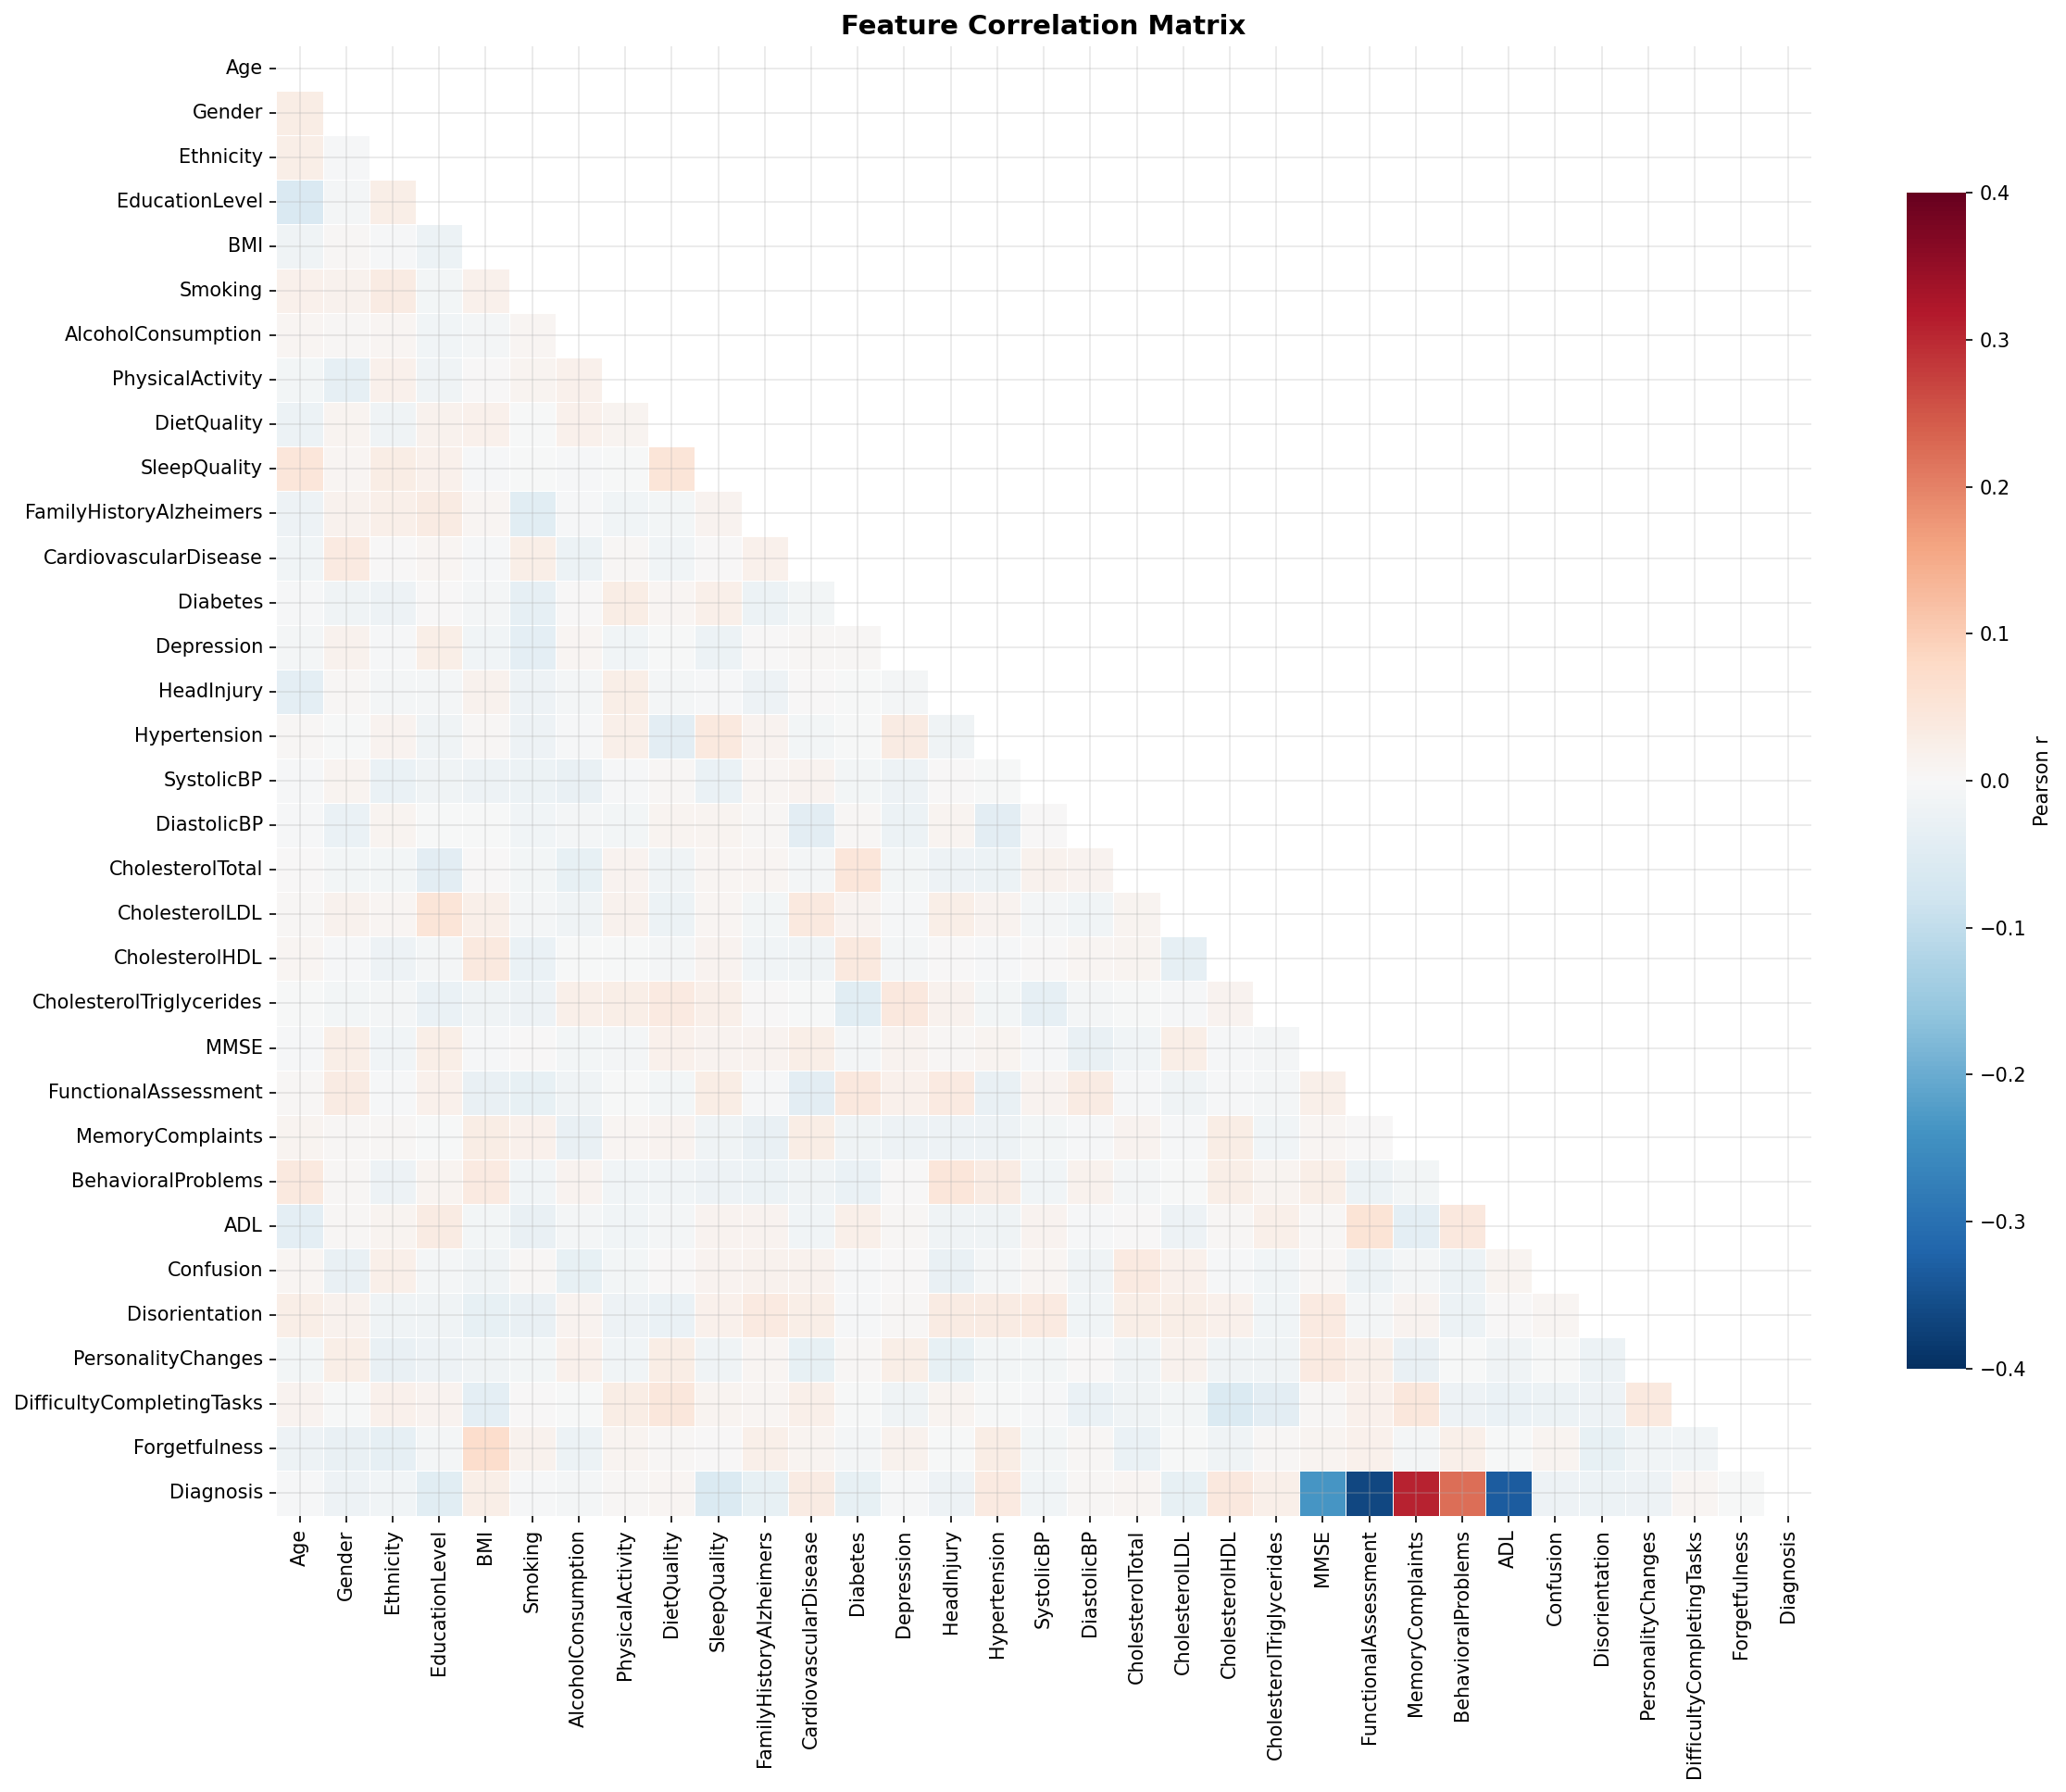

In [9]:
# ============================================================
# CELL 6 — EDA: Correlation heatmap
# ============================================================
corr = df[numeric_cols + ['Diagnosis']].corr()
target_corr = corr['Diagnosis'].drop('Diagnosis').abs().sort_values(ascending=False)
print("Top 10 features correlated with Diagnosis:")
print(target_corr.head(10).round(4))

fig, ax = plt.subplots(figsize=(16, 13))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='RdBu_r', center=0, linewidths=0.4,
            ax=ax, vmin=-0.4, vmax=0.4,
            cbar_kws={'label': 'Pearson r', 'shrink': 0.8})
ax.set_title('Feature Correlation Matrix', fontweight='bold', fontsize=14)
plt.tight_layout()
plt.savefig('outputs/02_correlation_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()



In [10]:
# ============================================================
# CELL 7 — EDA: Mann–Whitney U + Bonferroni
# ============================================================
test_feats = [f for f in ['MMSE', 'FunctionalAssessment', 'ADL',
                           'MemoryComplaints', 'BehavioralProblems'] if f in df.columns]
rows = []
for f in test_feats:
    g0 = df.loc[df.Diagnosis == 0, f].dropna()
    g1 = df.loc[df.Diagnosis == 1, f].dropna()
    u, p = mannwhitneyu(g0, g1, alternative='two-sided')
    p_bonf = min(p * len(test_feats), 1.0)
    rows.append({'Feature': f,
                 'Mean (No AD)': round(g0.mean(), 3),
                 'Mean (AD)': round(g1.mean(), 3),
                 'Median (No AD)': round(g0.median(), 3),
                 'Median (AD)': round(g1.median(), 3),
                 'U-stat': round(u, 1),
                 'p-value': f'{p:.2e}',
                 'p-Bonferroni': f'{p_bonf:.2e}',
                 'Significant': '✓' if p_bonf < 0.05 else '✗'})
mw_df = pd.DataFrame(rows)
print("Mann–Whitney U Test (Bonferroni corrected):")
print(mw_df.to_string(index=False))



Mann–Whitney U Test (Bonferroni corrected):
             Feature  Mean (No AD)  Mean (AD)  Median (No AD)  Median (AD)   U-stat  p-value p-Bonferroni Significant
                MMSE        16.266     11.995          17.146       11.566 678416.0 6.62e-28     3.31e-27           ✓
FunctionalAssessment         5.861      3.653           6.244        3.299 761542.0 9.00e-65     4.50e-64           ✓
                 ADL         5.708      3.658           6.135        3.236 738445.0 6.05e-53     3.03e-52           ✓
    MemoryComplaints         0.116      0.376           0.000        0.000 390373.0 7.25e-46     3.62e-45           ✓
  BehavioralProblems         0.096      0.267           0.000        0.000 437756.5 2.54e-25     1.27e-24           ✓


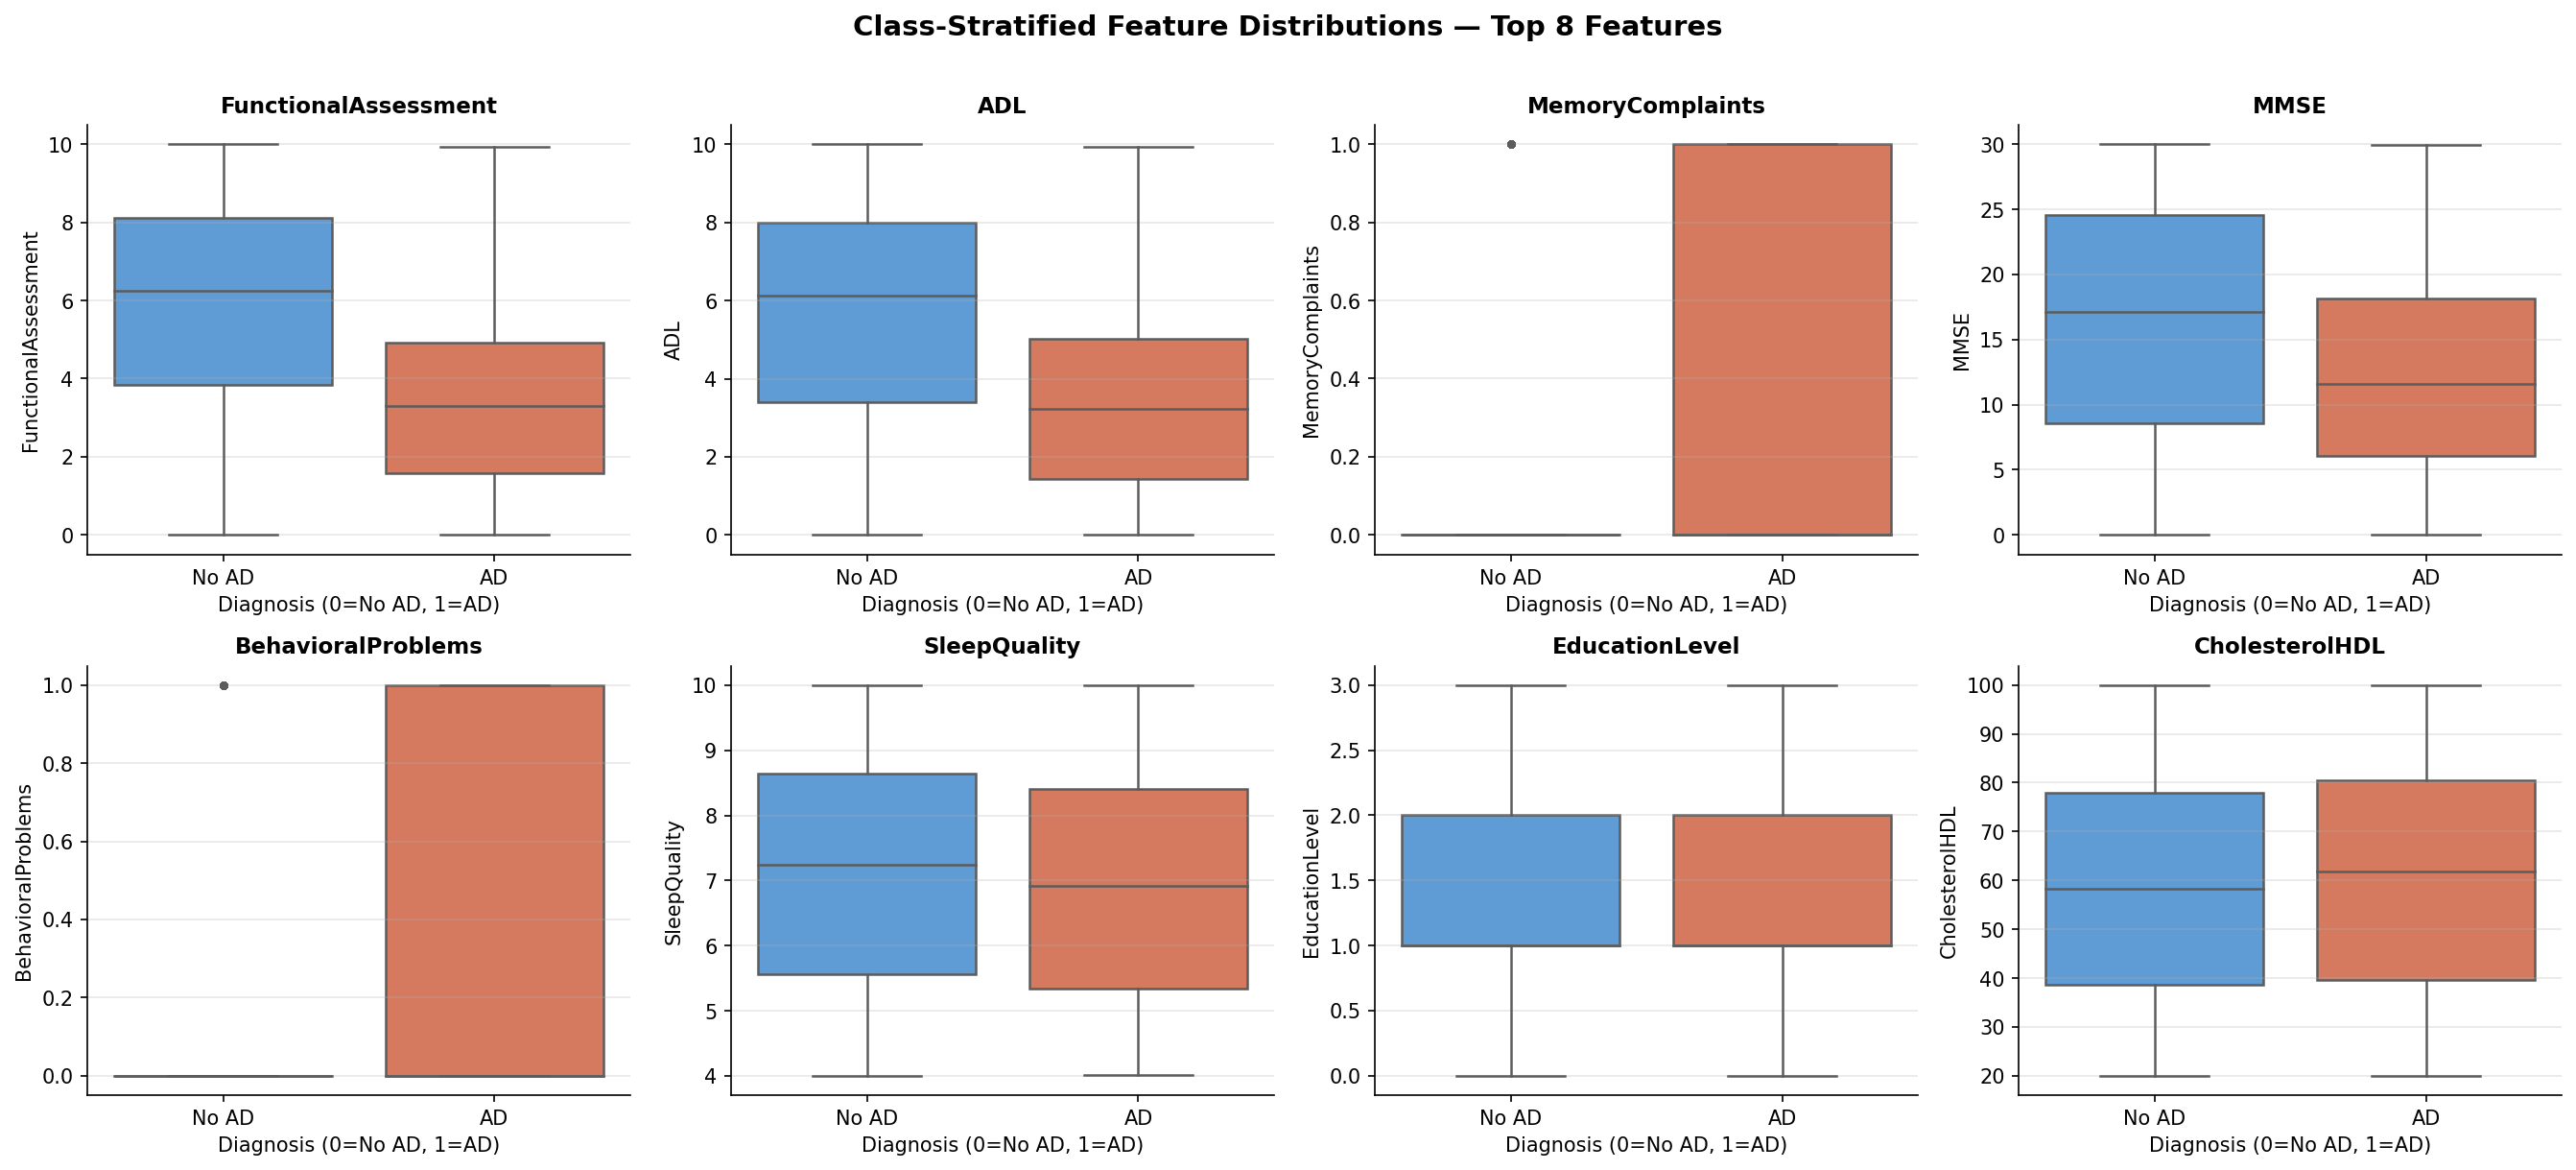

In [11]:
# ============================================================
# CELL 8 — EDA: Class-stratified boxplots
# ============================================================
top8 = target_corr.head(8).index.tolist()
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, feat in zip(axes.flatten(), top8):
    sns.boxplot(data=df, x='Diagnosis', y=feat,
                palette=PALETTE, ax=ax, linewidth=1.2,
                flierprops=dict(marker='o', markersize=3, alpha=0.5))
    ax.set_title(feat, fontweight='bold', fontsize=11)
    ax.set_xlabel('Diagnosis (0=No AD, 1=AD)')
    ax.set_xticklabels(['No AD', 'AD'])
plt.suptitle('Class-Stratified Feature Distributions — Top 8 Features',
             fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('outputs/03_stratified_boxplots.png', dpi=150, bbox_inches='tight')
plt.show()



In [12]:
# ============================================================
# CELL 9 — Preprocessing pipeline
# ============================================================
# --- Encode categoricals ---
cat_cols = df.select_dtypes('object').columns.tolist()
df_enc = pd.get_dummies(df, columns=cat_cols, drop_first=True) if cat_cols else df.copy()

X = df_enc.drop(columns=['Diagnosis'])
y = df_enc['Diagnosis'].astype(int)
scale_cols = [c for c in X.columns if c in numeric_cols]
other_cols = [c for c in X.columns if c not in scale_cols]

print(f"Features: {X.shape[1]} total | Continuous: {len(scale_cols)} | Binary/OHE: {len(other_cols)}")

# --- Stratified 80/20 split ---
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y)
print(f"Train: {X_train.shape[0]} | Test: {X_test.shape[0]}")
print(f"Train class dist: {dict(y_train.value_counts())} | Test: {dict(y_test.value_counts())}")

# --- Imputation (fit on train only) ---
imp = SimpleImputer(strategy='median')
X_train_imp = X_train.copy()
X_test_imp  = X_test.copy()
X_train_imp[scale_cols] = imp.fit_transform(X_train[scale_cols])
X_test_imp[scale_cols]  = imp.transform(X_test[scale_cols])

# --- Scaling (fit on train only) ---
scaler = StandardScaler()
X_train_s = X_train_imp.copy()
X_test_s  = X_test_imp.copy()
X_train_s[scale_cols] = scaler.fit_transform(X_train_imp[scale_cols])
X_test_s[scale_cols]  = scaler.transform(X_test_imp[scale_cols])

# --- SMOTE (training set only — post split) ---
sm = SMOTE(random_state=42)
X_tr_res,  y_tr_res  = sm.fit_resample(X_train_s,   y_train)   # scaled (LR, SVM, MLP, Stack)
X_tr_tree, y_tr_tree = sm.fit_resample(X_train_imp, y_train)   # unscaled (RF, XGB, LGB, CAT)

print(f"\nPost-SMOTE train size: {X_tr_res.shape[0]} | Class: {dict(pd.Series(y_tr_res).value_counts())}")



Features: 32 total | Continuous: 32 | Binary/OHE: 0
Train: 1719 | Test: 430
Train class dist: {0: 1111, 1: 608} | Test: {0: 278, 1: 152}

Post-SMOTE train size: 2222 | Class: {0: 1111, 1: 1111}


In [13]:
# ============================================================
# CELL 10 — Train all individual models + evaluate
# ============================================================
def full_eval(clf, Xtr, ytr, Xte, yte, name=""):
    clf.fit(Xtr, ytr)
    yp   = clf.predict(Xte)
    ypr  = clf.predict_proba(Xte)[:, 1]
    return clf, yp, ypr, {
        'Accuracy':  round(accuracy_score(yte, yp), 4),
        'Precision': round(precision_score(yte, yp, zero_division=0), 4),
        'Recall':    round(recall_score(yte, yp, zero_division=0), 4),
        'F1':        round(f1_score(yte, yp, average='weighted'), 4),
        'AUC':       round(roc_auc_score(yte, ypr), 4),
        'MCC':       round(matthews_corrcoef(yte, yp), 4),
    }

# Define base models
base_models = {
    'Logistic Regression':
        (LogisticRegression(max_iter=1000, random_state=42),
         X_tr_res, y_tr_res, X_test_s),

    'Random Forest':
        (RandomForestClassifier(n_estimators=200, random_state=42),
         X_tr_tree, y_tr_tree, X_test_imp),

    'XGBoost':
        (xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                            eval_metric='logloss', random_state=42, verbosity=0),
         X_tr_tree, y_tr_tree, X_test_imp),

    'LightGBM':
        (lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05,
                             random_state=42, verbose=-1),
         X_tr_tree, y_tr_tree, X_test_imp),

    'CatBoost':
        (cb.CatBoostClassifier(iterations=200, learning_rate=0.05,
                               random_seed=42, verbose=0),
         X_tr_tree, y_tr_tree, X_test_imp),

    'SVM (RBF)':
        (SVC(kernel='rbf', probability=True, random_state=42),
         X_tr_res, y_tr_res, X_test_s),

    'MLP':
        (MLPClassifier(hidden_layer_sizes=(128, 64), max_iter=500,
                       random_state=42),
         X_tr_res, y_tr_res, X_test_s),
}

results  = {}
cms      = {}
probas   = {}
fitted   = {}

print("Training individual models...\n")
for name, (clf, Xtr, ytr, Xte) in base_models.items():
    clf_fit, yp, ypr, met = full_eval(clf, Xtr, ytr, Xte, y_test, name)
    results[name] = met
    cms[name]     = confusion_matrix(y_test, yp)
    probas[name]  = ypr
    fitted[name]  = clf_fit
    print(f"  {name:<22}  AUC={met['AUC']:.4f}  MCC={met['MCC']:.4f}  F1={met['F1']:.4f}")

results_df = pd.DataFrame(results).T
print("\n── Individual Model Comparison ──")
print(results_df.to_string())



Training individual models...

  Logistic Regression     AUC=0.8865  MCC=0.6270  F1=0.8196
  Random Forest           AUC=0.9419  MCC=0.8826  F1=0.9464
  XGBoost                 AUC=0.9480  MCC=0.8875  F1=0.9486
  LightGBM                AUC=0.9503  MCC=0.8876  F1=0.9487
  CatBoost                AUC=0.9414  MCC=0.8828  F1=0.9465
  SVM (RBF)               AUC=0.8972  MCC=0.6820  F1=0.8540
  MLP                     AUC=0.8653  MCC=0.5567  F1=0.7975

── Individual Model Comparison ──
                     Accuracy  Precision  Recall      F1     AUC     MCC
Logistic Regression    0.8163     0.6952  0.8553  0.8196  0.8865  0.6270
Random Forest          0.9465     0.9329  0.9145  0.9464  0.9419  0.8826
XGBoost                0.9488     0.9452  0.9079  0.9486  0.9480  0.8875
LightGBM               0.9488     0.9392  0.9145  0.9487  0.9503  0.8876
CatBoost               0.9465     0.9272  0.9211  0.9465  0.9414  0.8828
SVM (RBF)              0.8535     0.7834  0.8092  0.8540  0.8972  0.6820
MLP

In [14]:
# ============================================================
# CELL 11 — PROPOSED METHOD: Stacking Ensemble
# ============================================================
print("\nBuilding stacking ensemble (RF + XGB + LGB + CAT → LR meta-learner)...\n")

# Base estimators for stacking — use unscaled data (tree models)
stack_estimators = [
    ('rf',  RandomForestClassifier(n_estimators=200, random_state=42)),
    ('xgb', xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                               eval_metric='logloss', random_state=42, verbosity=0)),
    ('lgb', lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05,
                                random_state=42, verbose=-1)),
    ('cat', cb.CatBoostClassifier(iterations=200, learning_rate=0.05,
                                  random_seed=42, verbose=0)),
]

stack_clf = StackingClassifier(
    estimators=stack_estimators,
    final_estimator=LogisticRegression(max_iter=1000, C=1.0, random_state=42),
    cv=5,
    stack_method='predict_proba',
    n_jobs=-1,
    passthrough=False
)

stack_clf.fit(X_tr_tree, y_tr_tree)
yp_stack  = stack_clf.predict(X_test_imp)
ypr_stack = stack_clf.predict_proba(X_test_imp)[:, 1]

stack_met = {
    'Accuracy':  round(accuracy_score(y_test, yp_stack), 4),
    'Precision': round(precision_score(y_test, yp_stack, zero_division=0), 4),
    'Recall':    round(recall_score(y_test, yp_stack, zero_division=0), 4),
    'F1':        round(f1_score(y_test, yp_stack, average='weighted'), 4),
    'AUC':       round(roc_auc_score(y_test, ypr_stack), 4),
    'MCC':       round(matthews_corrcoef(y_test, yp_stack), 4),
}

results['Stacking Ensemble'] = stack_met
cms['Stacking Ensemble']     = confusion_matrix(y_test, yp_stack)
probas['Stacking Ensemble']  = ypr_stack

print("── STACKING ENSEMBLE RESULTS ──")
for k, v in stack_met.items():
    print(f"  {k:<12}: {v}")

# Full updated table
results_df = pd.DataFrame(results).T
print("\n── Full Model Comparison Table (including Ensemble) ──")
print(results_df.to_string())




Building stacking ensemble (RF + XGB + LGB + CAT → LR meta-learner)...

── STACKING ENSEMBLE RESULTS ──
  Accuracy    : 0.9512
  Precision   : 0.9396
  Recall      : 0.9211
  F1          : 0.9511
  AUC         : 0.9429
  MCC         : 0.8928

── Full Model Comparison Table (including Ensemble) ──
                     Accuracy  Precision  Recall      F1     AUC     MCC
Logistic Regression    0.8163     0.6952  0.8553  0.8196  0.8865  0.6270
Random Forest          0.9465     0.9329  0.9145  0.9464  0.9419  0.8826
XGBoost                0.9488     0.9452  0.9079  0.9486  0.9480  0.8875
LightGBM               0.9488     0.9392  0.9145  0.9487  0.9503  0.8876
CatBoost               0.9465     0.9272  0.9211  0.9465  0.9414  0.8828
SVM (RBF)              0.8535     0.7834  0.8092  0.8540  0.8972  0.6820
MLP                    0.7977     0.7152  0.7105  0.7975  0.8653  0.5567
Stacking Ensemble      0.9512     0.9396  0.9211  0.9511  0.9429  0.8928


In [15]:
# ============================================================
# CELL 12 — Ablation Study
# ============================================================
print("\n── ABLATION STUDY ──\n")

ablation = {}

# A1: XGBoost WITHOUT SMOTE
xgb_ns = xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                             eval_metric='logloss', random_state=42, verbosity=0)
xgb_ns.fit(X_train_imp, y_train)
yp_ns  = xgb_ns.predict(X_test_imp)
ypr_ns = xgb_ns.predict_proba(X_test_imp)[:, 1]
ablation['XGB — No SMOTE'] = {
    'AUC':    round(roc_auc_score(y_test, ypr_ns), 4),
    'Recall': round(recall_score(y_test, yp_ns), 4),
    'MCC':    round(matthews_corrcoef(y_test, yp_ns), 4),
    'F1':     round(f1_score(y_test, yp_ns, average='weighted'), 4),
}

# A2: XGBoost WITH SMOTE (already trained)
ablation['XGB — With SMOTE'] = {
    'AUC':    results['XGBoost']['AUC'],
    'Recall': results['XGBoost']['Recall'],
    'MCC':    results['XGBoost']['MCC'],
    'F1':     results['XGBoost']['F1'],
}

# A3: Ensemble WITHOUT SMOTE
stack_ns = StackingClassifier(
    estimators=[
        ('rf',  RandomForestClassifier(n_estimators=200, random_state=42)),
        ('xgb', xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                                   eval_metric='logloss', random_state=42, verbosity=0)),
        ('lgb', lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05,
                                    random_state=42, verbose=-1)),
        ('cat', cb.CatBoostClassifier(iterations=200, learning_rate=0.05,
                                      random_seed=42, verbose=0)),
    ],
    final_estimator=LogisticRegression(max_iter=1000, random_state=42),
    cv=5, stack_method='predict_proba', n_jobs=-1
)
stack_ns.fit(X_train_imp, y_train)
yp_sns  = stack_ns.predict(X_test_imp)
ypr_sns = stack_ns.predict_proba(X_test_imp)[:, 1]
ablation['Ensemble — No SMOTE'] = {
    'AUC':    round(roc_auc_score(y_test, ypr_sns), 4),
    'Recall': round(recall_score(y_test, yp_sns), 4),
    'MCC':    round(matthews_corrcoef(y_test, yp_sns), 4),
    'F1':     round(f1_score(y_test, yp_sns, average='weighted'), 4),
}

# A4: Ensemble WITH SMOTE
ablation['Ensemble — With SMOTE'] = {
    'AUC':    stack_met['AUC'],
    'Recall': stack_met['Recall'],
    'MCC':    stack_met['MCC'],
    'F1':     stack_met['F1'],
}

# A5: Only cognitive features
cog_feats = [f for f in ['MMSE', 'MemoryComplaints'] if f in X_test_imp.columns]
xgb_cog = xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                              eval_metric='logloss', random_state=42, verbosity=0)
xgb_cog.fit(X_tr_tree[cog_feats], y_tr_tree)
yp_cog  = xgb_cog.predict(X_test_imp[cog_feats])
ypr_cog = xgb_cog.predict_proba(X_test_imp[cog_feats])[:, 1]
ablation['XGB — Cognitive Only'] = {
    'AUC':    round(roc_auc_score(y_test, ypr_cog), 4),
    'Recall': round(recall_score(y_test, yp_cog), 4),
    'MCC':    round(matthews_corrcoef(y_test, yp_cog), 4),
    'F1':     round(f1_score(y_test, yp_cog, average='weighted'), 4),
}

# A6: Only functional features
func_feats = [f for f in ['FunctionalAssessment', 'ADL', 'BehavioralProblems']
              if f in X_test_imp.columns]
xgb_func = xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                               eval_metric='logloss', random_state=42, verbosity=0)
xgb_func.fit(X_tr_tree[func_feats], y_tr_tree)
yp_func  = xgb_func.predict(X_test_imp[func_feats])
ypr_func = xgb_func.predict_proba(X_test_imp[func_feats])[:, 1]
ablation['XGB — Functional Only'] = {
    'AUC':    round(roc_auc_score(y_test, ypr_func), 4),
    'Recall': round(recall_score(y_test, yp_func), 4),
    'MCC':    round(matthews_corrcoef(y_test, yp_func), 4),
    'F1':     round(f1_score(y_test, yp_func, average='weighted'), 4),
}

# A7: Remove top SHAP feature (FunctionalAssessment)
feats_no_fa = [c for c in X_test_imp.columns if c != 'FunctionalAssessment']
xgb_nofa = xgb.XGBClassifier(n_estimators=200, learning_rate=0.05,
                               eval_metric='logloss', random_state=42, verbosity=0)
xgb_nofa.fit(X_tr_tree[feats_no_fa], y_tr_tree)
yp_nofa  = xgb_nofa.predict(X_test_imp[feats_no_fa])
ypr_nofa = xgb_nofa.predict_proba(X_test_imp[feats_no_fa])[:, 1]
ablation['XGB — Drop FunctionalAssess.'] = {
    'AUC':    round(roc_auc_score(y_test, ypr_nofa), 4),
    'Recall': round(recall_score(y_test, yp_nofa), 4),
    'MCC':    round(matthews_corrcoef(y_test, yp_nofa), 4),
    'F1':     round(f1_score(y_test, yp_nofa, average='weighted'), 4),
}

abl_df = pd.DataFrame(ablation).T
print(abl_df.to_string())




── ABLATION STUDY ──

                                 AUC  Recall     MCC      F1
XGB — No SMOTE                0.9455  0.9079  0.8824  0.9463
XGB — With SMOTE              0.9480  0.9079  0.8875  0.9486
Ensemble — No SMOTE           0.9414  0.9211  0.8928  0.9511
Ensemble — With SMOTE         0.9429  0.9211  0.8928  0.9511
XGB — Cognitive Only          0.7129  0.4408  0.2621  0.6669
XGB — Functional Only         0.8287  0.7566  0.5586  0.7950
XGB — Drop FunctionalAssess.  0.8639  0.7171  0.5536  0.7956


In [16]:
# ============================================================
# CELL 13 — Statistical significance testing (McNemar's)
# ============================================================
print("\n── STATISTICAL SIGNIFICANCE TESTING ──\n")

# Best model: Stacking Ensemble vs XGBoost
yp_xgb    = fitted['XGBoost'].predict(X_test_imp)
yp_ens    = yp_stack

correct_ens = (yp_ens == np.array(y_test))
correct_xgb = (yp_xgb == np.array(y_test))

b = int(np.sum( correct_ens & ~correct_xgb))   # Ensemble right, XGB wrong
c = int(np.sum(~correct_ens &  correct_xgb))   # Ensemble wrong, XGB right

print(f"McNemar contingency: b={b} (Ensemble✓ XGB✗), c={c} (Ensemble✗ XGB✓)")

if b + c > 0:
    table = [[0, b], [c, 0]]
    result = mcnemar(table, exact=(b + c < 25), correction=True)
    print(f"McNemar's test: statistic={result.statistic:.4f}, p-value={result.pvalue:.4f}")
    if result.pvalue < 0.05:
        print("→ Stacking Ensemble is SIGNIFICANTLY better than XGBoost (p < 0.05)")
    else:
        print("→ Difference is NOT statistically significant — performance is comparable")
else:
    print("→ Identical predictions — McNemar's test not applicable")

# Ensemble vs RF
yp_rf   = fitted['Random Forest'].predict(X_test_imp)
b2 = int(np.sum( correct_ens & (yp_rf != np.array(y_test))))
c2 = int(np.sum(~correct_ens & (yp_rf == np.array(y_test))))
print(f"\nEnsemble vs RF: b={b2}, c={c2}")
if b2 + c2 > 0:
    result2 = mcnemar([[0, b2], [c2, 0]], exact=(b2 + c2 < 25), correction=True)
    print(f"McNemar's test: statistic={result2.statistic:.4f}, p-value={result2.pvalue:.4f}")




── STATISTICAL SIGNIFICANCE TESTING ──

McNemar contingency: b=3 (Ensemble✓ XGB✗), c=2 (Ensemble✗ XGB✓)
McNemar's test: statistic=2.0000, p-value=1.0000
→ Difference is NOT statistically significant — performance is comparable

Ensemble vs RF: b=3, c=1
McNemar's test: statistic=1.0000, p-value=0.6250


In [17]:
# ============================================================
# CELL 14 — 5-Fold Stratified CV for all models
# ============================================================
print("\n── 5-FOLD STRATIFIED CROSS-VALIDATION ──\n")
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}

cv_models = {
    'Logistic Regression': (LogisticRegression(max_iter=1000, random_state=42),          X_tr_res,  y_tr_res),
    'Random Forest':       (RandomForestClassifier(n_estimators=200, random_state=42),   X_tr_tree, y_tr_tree),
    'XGBoost':             (xgb.XGBClassifier(n_estimators=200, learning_rate=0.05, eval_metric='logloss', random_state=42, verbosity=0), X_tr_tree, y_tr_tree),
    'LightGBM':            (lgb.LGBMClassifier(n_estimators=200, learning_rate=0.05, random_state=42, verbose=-1), X_tr_tree, y_tr_tree),
    'CatBoost':            (cb.CatBoostClassifier(iterations=200, learning_rate=0.05, random_seed=42, verbose=0), X_tr_tree, y_tr_tree),
    'SVM (RBF)':           (SVC(kernel='rbf', probability=True, random_state=42),         X_tr_res,  y_tr_res),
    'MLP':                 (MLPClassifier(hidden_layer_sizes=(128,64), max_iter=500, random_state=42), X_tr_res, y_tr_res),
    'Stacking Ensemble':   (StackingClassifier(
        estimators=[
            ('rf',  RandomForestClassifier(n_estimators=100, random_state=42)),
            ('xgb', xgb.XGBClassifier(n_estimators=100, learning_rate=0.05, eval_metric='logloss', random_state=42, verbosity=0)),
            ('lgb', lgb.LGBMClassifier(n_estimators=100, learning_rate=0.05, random_state=42, verbose=-1)),
            ('cat', cb.CatBoostClassifier(iterations=100, learning_rate=0.05, random_seed=42, verbose=0)),
        ],
        final_estimator=LogisticRegression(max_iter=1000, random_state=42),
        cv=3, stack_method='predict_proba', n_jobs=-1), X_tr_tree, y_tr_tree),
}

for name, (clf, Xtr, ytr) in cv_models.items():
    cv_out = cross_validate(clf, Xtr, ytr, cv=skf,
                            scoring=['roc_auc', 'f1_weighted', 'matthews_corrcoef'],
                            n_jobs=-1)
    cv_results[name] = {
        'AUC μ':  round(cv_out['test_roc_auc'].mean(), 4),
        'AUC σ':  round(cv_out['test_roc_auc'].std(), 4),
        'F1 μ':   round(cv_out['test_f1_weighted'].mean(), 4),
        'F1 σ':   round(cv_out['test_f1_weighted'].std(), 4),
        'MCC μ':  round(cv_out['test_matthews_corrcoef'].mean(), 4),
        'MCC σ':  round(cv_out['test_matthews_corrcoef'].std(), 4),
    }
    print(f"  {name:<22}  AUC={cv_results[name]['AUC μ']:.4f}±{cv_results[name]['AUC σ']:.4f}"
          f"  F1={cv_results[name]['F1 μ']:.4f}±{cv_results[name]['F1 σ']:.4f}")

cv_df = pd.DataFrame(cv_results).T
print("\nFull CV Table:")
print(cv_df.to_string())




── 5-FOLD STRATIFIED CROSS-VALIDATION ──

  Logistic Regression     AUC=0.9146±0.0118  F1=0.8423±0.0124
  Random Forest           AUC=0.9727±0.0092  F1=0.9527±0.0117
  XGBoost                 AUC=0.9747±0.0084  F1=0.9568±0.0087
  LightGBM                AUC=0.9756±0.0082  F1=0.9581±0.0074
  CatBoost                AUC=0.9744±0.0090  F1=0.9581±0.0105
  SVM (RBF)               AUC=0.9432±0.0107  F1=0.8815±0.0169
  MLP                     AUC=0.9320±0.0132  F1=0.8652±0.0191
  Stacking Ensemble       AUC=0.9736±0.0090  F1=0.9568±0.0090

Full CV Table:
                      AUC μ   AUC σ    F1 μ    F1 σ   MCC μ   MCC σ
Logistic Regression  0.9146  0.0118  0.8423  0.0124  0.6865  0.0235
Random Forest        0.9727  0.0092  0.9527  0.0117  0.9066  0.0229
XGBoost              0.9747  0.0084  0.9568  0.0087  0.9142  0.0173
LightGBM             0.9756  0.0082  0.9581  0.0074  0.9168  0.0144
CatBoost             0.9744  0.0090  0.9581  0.0105  0.9169  0.0210
SVM (RBF)            0.9432  0.0107  

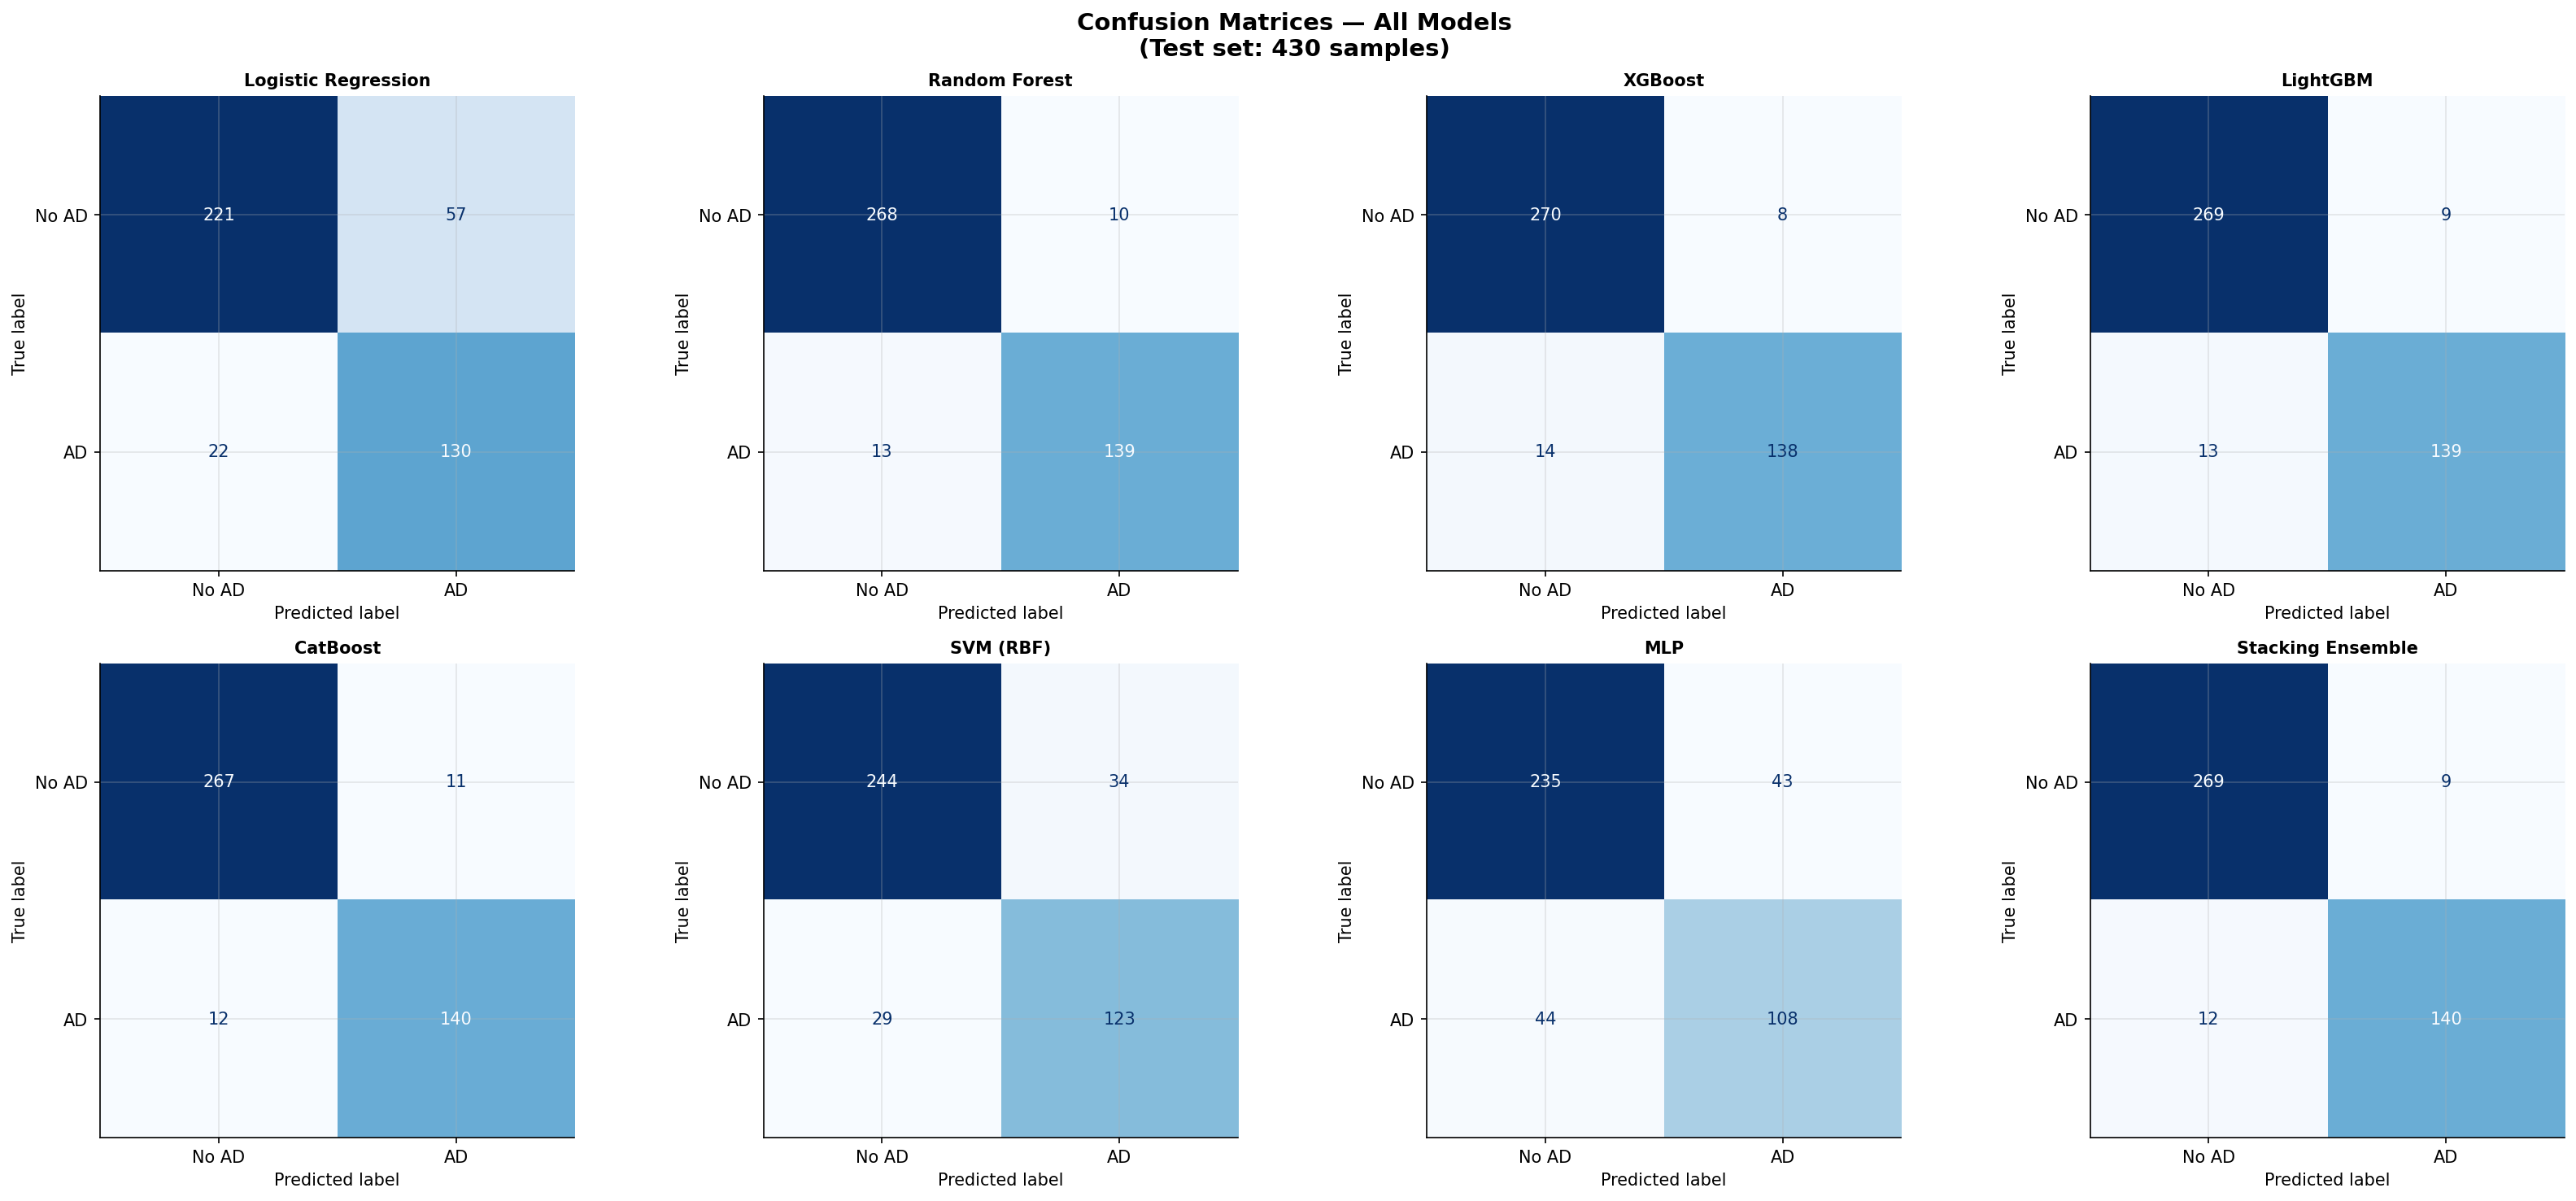

In [18]:
# ============================================================
# CELL 15 — Confusion matrices (all models)
# ============================================================
all_model_names = list(base_models.keys()) + ['Stacking Ensemble']
n_models = len(all_model_names)
fig, axes = plt.subplots(2, 4, figsize=(22, 10))
axes_flat = axes.flatten()

for i, name in enumerate(all_model_names):
    if i >= len(axes_flat): break
    disp = ConfusionMatrixDisplay(cms[name], display_labels=['No AD', 'AD'])
    disp.plot(ax=axes_flat[i], colorbar=False, cmap='Blues')
    axes_flat[i].set_title(name, fontsize=10, fontweight='bold')

# Hide unused subplot
if n_models < len(axes_flat):
    for j in range(n_models, len(axes_flat)):
        axes_flat[j].set_visible(False)

plt.suptitle('Confusion Matrices — All Models\n(Test set: 430 samples)',
             fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/04_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()



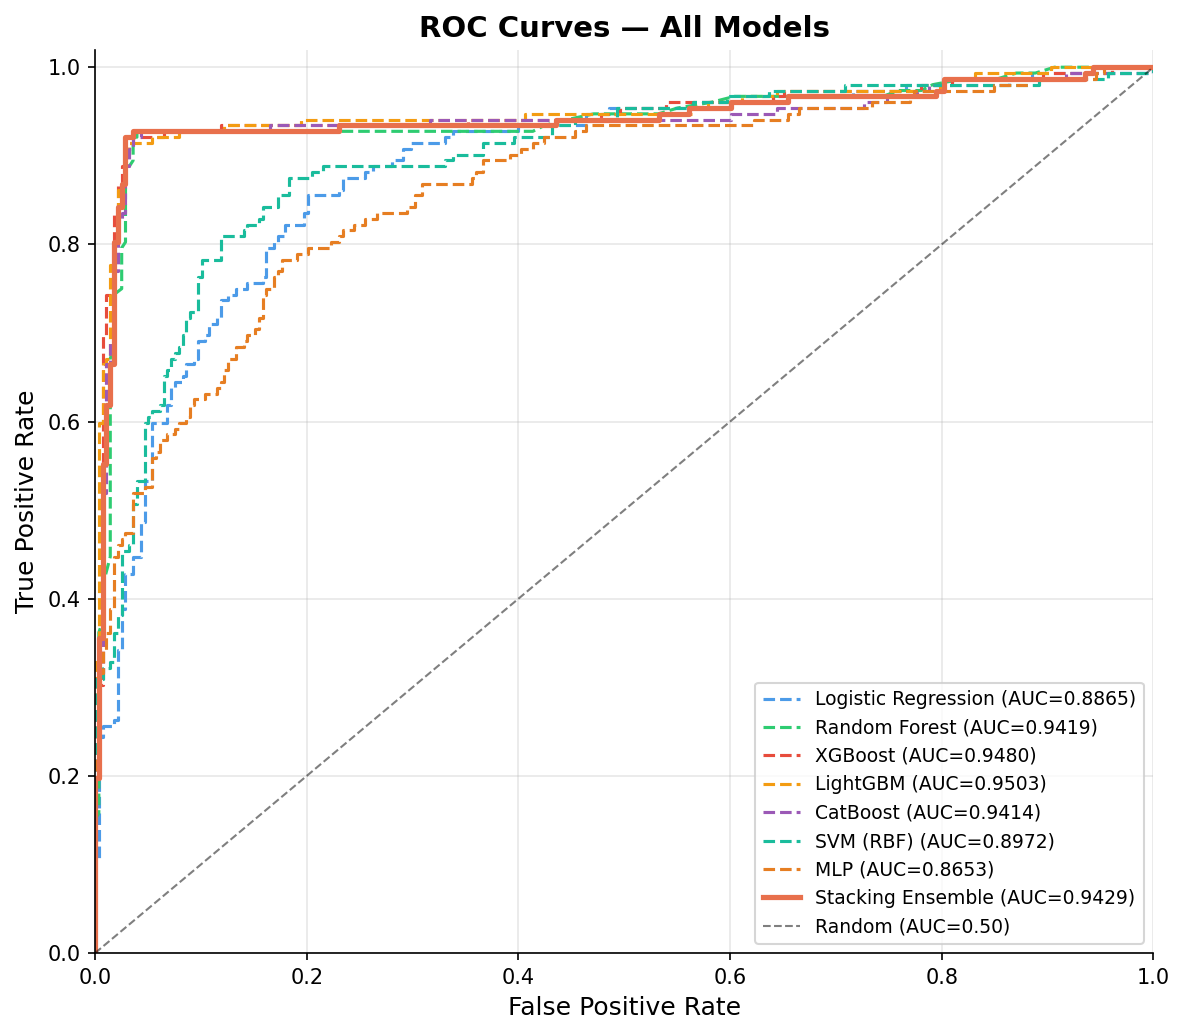

In [19]:
# ============================================================
# CELL 16 — ROC curves (all models on one plot)
# ============================================================
fig, ax = plt.subplots(figsize=(8, 7))
colors = ['#4C9BE8', '#2ECC71', '#E74C3C', '#F39C12', '#9B59B6',
          '#1ABC9C', '#E67E22', '#E8704C']

for (name, ypr), color in zip(probas.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, ypr)
    roc_auc = auc(fpr, tpr)
    lw = 2.5 if name == 'Stacking Ensemble' else 1.5
    ls = '-' if name == 'Stacking Ensemble' else '--'
    ax.plot(fpr, tpr, color=color, lw=lw, linestyle=ls,
            label=f'{name} (AUC={roc_auc:.4f})')

ax.plot([0, 1], [0, 1], 'k--', lw=1, alpha=0.5, label='Random (AUC=0.50)')
ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title('ROC Curves — All Models', fontsize=14, fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
ax.set_xlim([0, 1]); ax.set_ylim([0, 1.02])
plt.tight_layout()
plt.savefig('outputs/05_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()



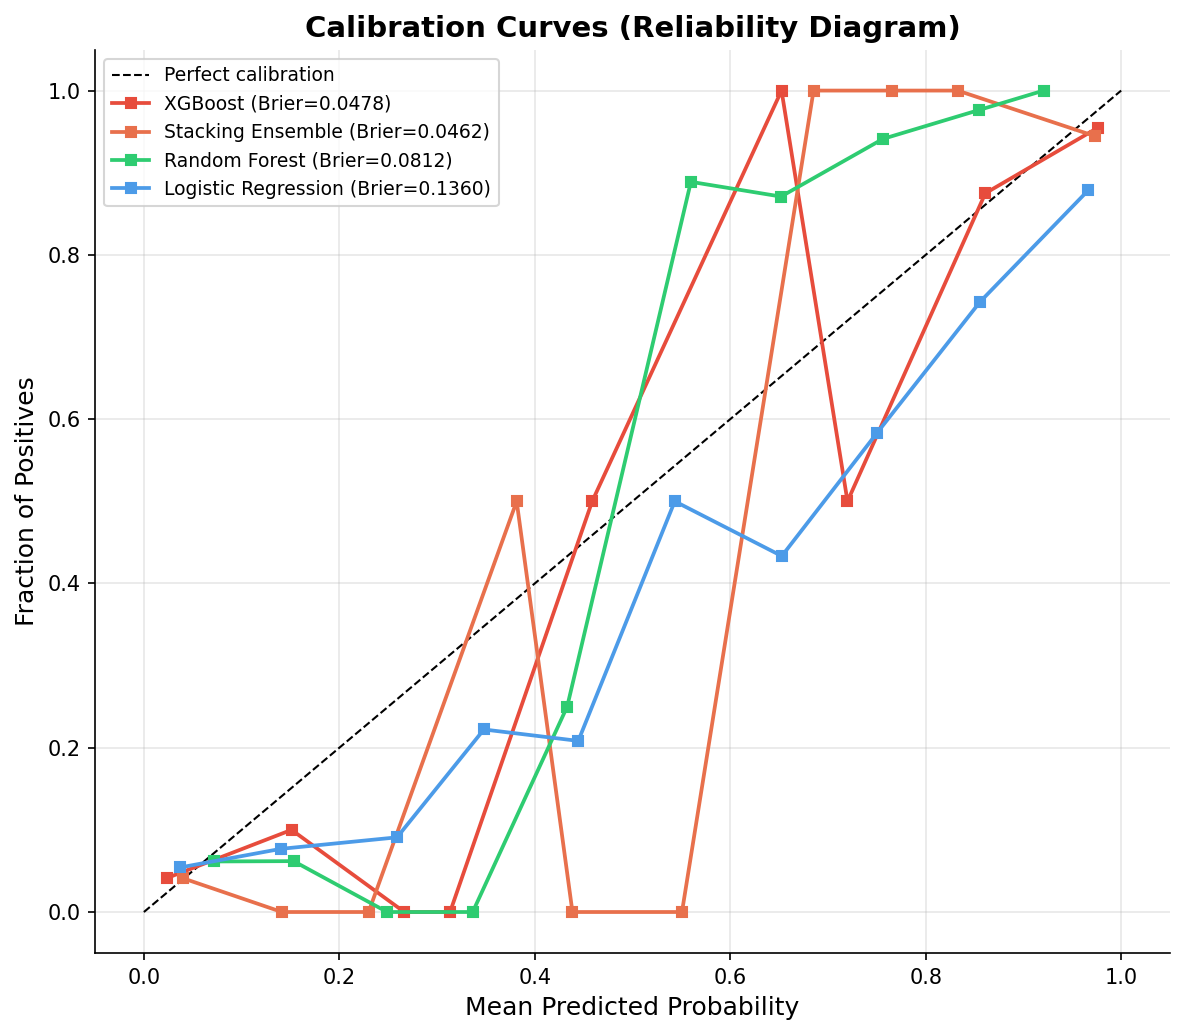


Brier Scores (lower = better calibrated):
  XGBoost               : 0.0478
  Stacking Ensemble     : 0.0462
  Random Forest         : 0.0812
  Logistic Regression   : 0.1360


In [20]:
# ============================================================
# CELL 17 — Calibration analysis (Reliability diagram)
# ============================================================
fig, ax = plt.subplots(figsize=(8, 7))
ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Perfect calibration')

cal_models = {
    'XGBoost': probas['XGBoost'],
    'Stacking Ensemble': probas['Stacking Ensemble'],
    'Random Forest': probas['Random Forest'],
    'Logistic Regression': probas['Logistic Regression'],
}

colors_cal = ['#E74C3C', '#E8704C', '#2ECC71', '#4C9BE8']
for (name, ypr), color in zip(cal_models.items(), colors_cal):
    prob_true, prob_pred = calibration_curve(y_test, ypr, n_bins=10)
    brier = brier_score_loss(y_test, ypr)
    ax.plot(prob_pred, prob_true, 's-', color=color, lw=1.8, markersize=5,
            label=f'{name} (Brier={brier:.4f})')

ax.set_xlabel('Mean Predicted Probability', fontsize=12)
ax.set_ylabel('Fraction of Positives', fontsize=12)
ax.set_title('Calibration Curves (Reliability Diagram)', fontsize=14, fontweight='bold')
ax.legend(fontsize=9)
plt.tight_layout()
plt.savefig('outputs/06_calibration_curves.png', dpi=150, bbox_inches='tight')
plt.show()

# Brier scores
print("\nBrier Scores (lower = better calibrated):")
for name, ypr in cal_models.items():
    print(f"  {name:<22}: {brier_score_loss(y_test, ypr):.4f}")



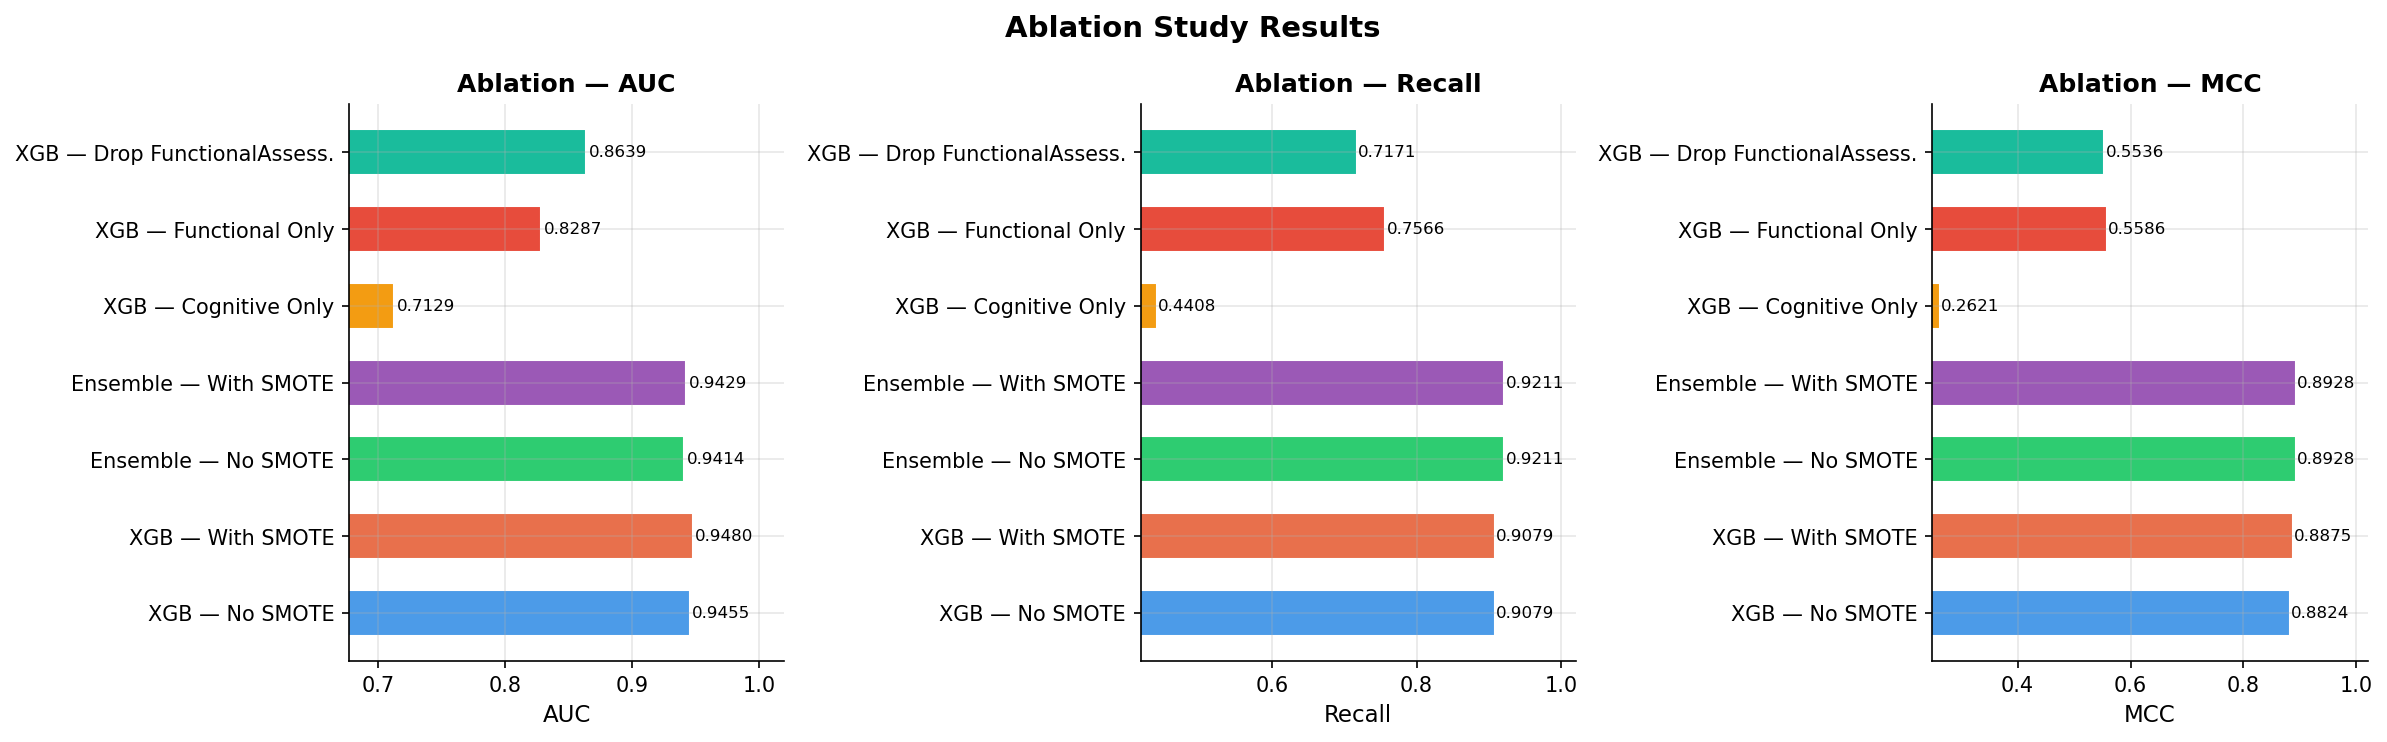

In [21]:
# ============================================================
# CELL 18 — Ablation bar chart
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
metrics = ['AUC', 'Recall', 'MCC']
colors_abl = ['#4C9BE8', '#E8704C', '#2ECC71', '#9B59B6', '#F39C12', '#E74C3C', '#1ABC9C']

for ax, metric in zip(axes, metrics):
    vals  = [abl_df.loc[m, metric] for m in abl_df.index]
    bars  = ax.barh(abl_df.index, vals, color=colors_abl[:len(vals)],
                    edgecolor='white', height=0.6)
    ax.set_xlabel(metric, fontsize=11)
    ax.set_title(f'Ablation — {metric}', fontweight='bold')
    ax.set_xlim(min(vals) * 0.95, 1.02)
    for bar, val in zip(bars, vals):
        ax.text(val + 0.002, bar.get_y() + bar.get_height()/2,
                f'{val:.4f}', va='center', fontsize=8)

plt.suptitle('Ablation Study Results', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('outputs/07_ablation_study.png', dpi=150, bbox_inches='tight')
plt.show()



In [22]:
# ============================================================
# CELL 19 — SHAP on Stacking Ensemble (best model)
# ============================================================
feat_names = list(X_test_imp.columns)
Xte_arr    = np.array(X_test_imp)
Xtr_arr    = np.array(X_tr_tree)

print("Computing SHAP values for Stacking Ensemble...")
print("(Using KernelExplainer with 150-sample background — may take 2–3 minutes)")

# Use a background sample for KernelExplainer
background = shap.sample(Xtr_arr, 150, random_state=42)

def ensemble_predict_proba(X):
    return stack_clf.predict_proba(X)[:, 1]

explainer_ens = shap.KernelExplainer(ensemble_predict_proba, background)
sv_ens = explainer_ens.shap_values(Xte_arr, nsamples=300, l1_reg='num_features(20)')

print(f"SHAP values shape: {np.array(sv_ens).shape}")



Using 150 background data samples could cause slower run times. Consider using shap.sample(data, K) or shap.kmeans(data, K) to summarize the background as K samples.


Computing SHAP values for Stacking Ensemble...
(Using KernelExplainer with 150-sample background — may take 2–3 minutes)


  0%|          | 0/430 [00:00<?, ?it/s]

SHAP values shape: (430, 32)


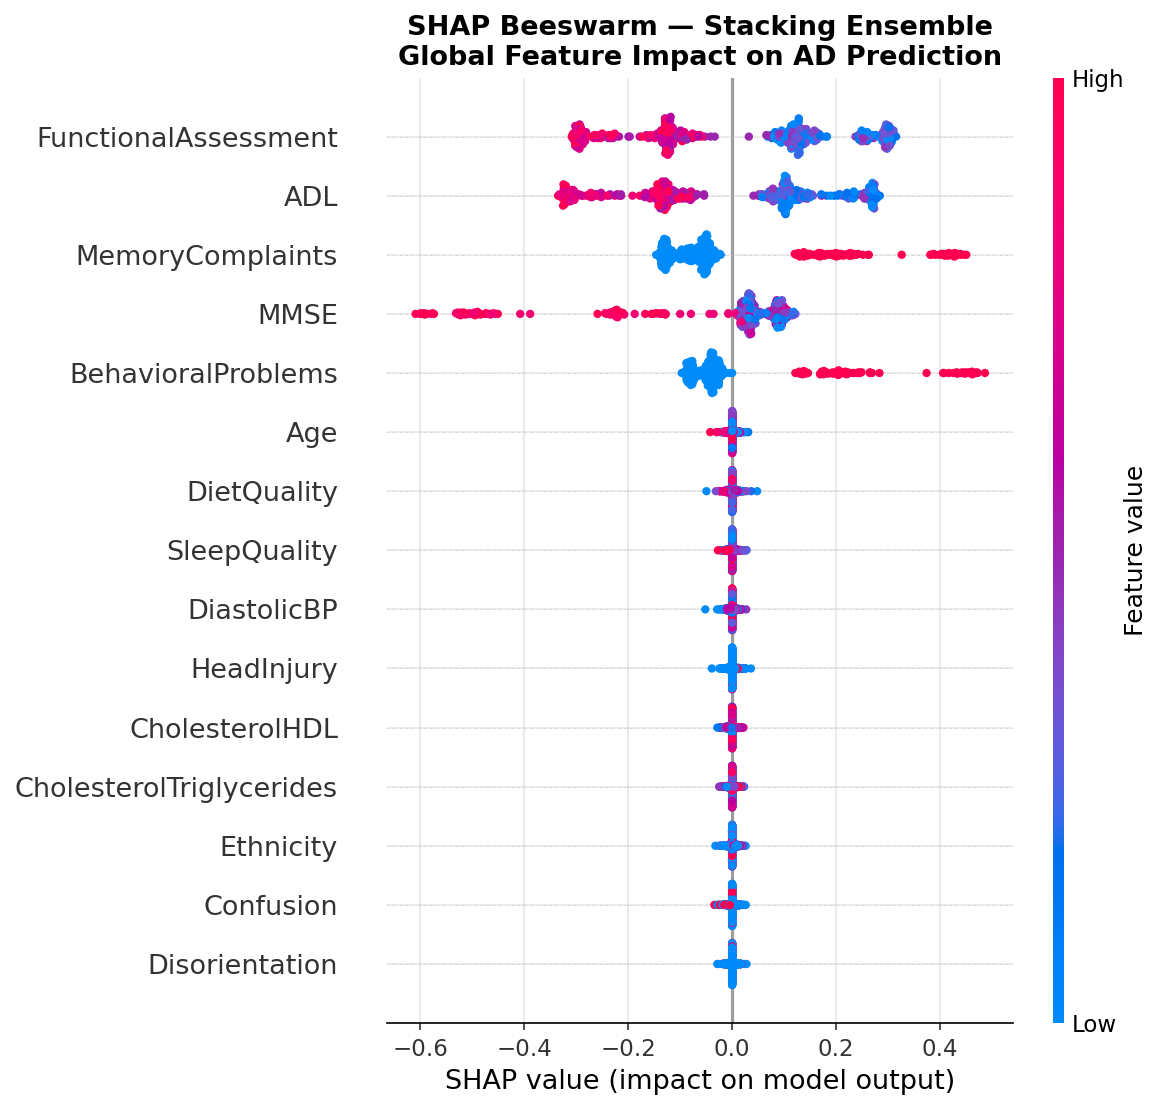

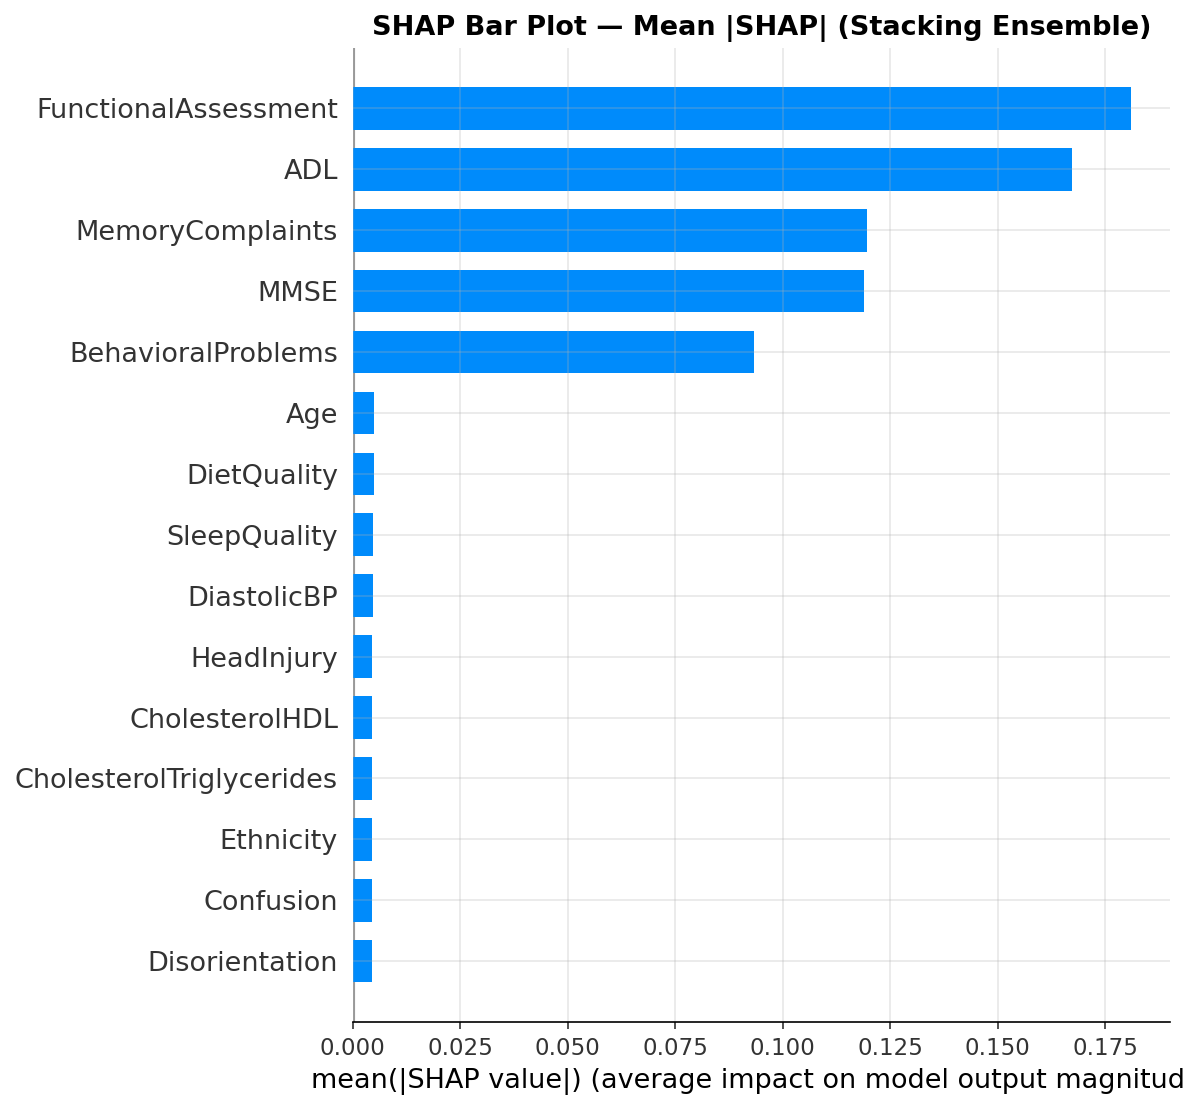


Biomarker Ranking by Mean |SHAP|:
FunctionalAssessment        0.18099
ADL                         0.16730
MemoryComplaints            0.11953
MMSE                        0.11895
BehavioralProblems          0.09334
Age                         0.00501
DietQuality                 0.00490
SleepQuality                0.00479
DiastolicBP                 0.00464
HeadInjury                  0.00457
CholesterolHDL              0.00454
CholesterolTriglycerides    0.00450
Ethnicity                   0.00449
Confusion                   0.00448
Disorientation              0.00445
dtype: float64


In [23]:
# ============================================================
# CELL 20 — SHAP global: Beeswarm + Bar
# ============================================================
sv = np.array(sv_ens)

# Beeswarm
plt.figure(figsize=(10, 8))
shap.summary_plot(sv, Xte_arr, feature_names=feat_names,
                  show=False, max_display=15, plot_type='dot')
plt.title('SHAP Beeswarm — Stacking Ensemble\nGlobal Feature Impact on AD Prediction',
          fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('outputs/08_shap_beeswarm.png', dpi=150, bbox_inches='tight')
plt.show()

# Bar plot
plt.figure(figsize=(10, 7))
shap.summary_plot(sv, Xte_arr, feature_names=feat_names,
                  show=False, max_display=15, plot_type='bar')
plt.title('SHAP Bar Plot — Mean |SHAP| (Stacking Ensemble)', fontweight='bold', fontsize=13)
plt.tight_layout()
plt.savefig('outputs/09_shap_bar.png', dpi=150, bbox_inches='tight')
plt.show()

# Biomarker ranking
shap_imp = pd.Series(np.abs(sv).mean(axis=0), index=feat_names).sort_values(ascending=False)
print("\nBiomarker Ranking by Mean |SHAP|:")
print(shap_imp.head(15).round(5))



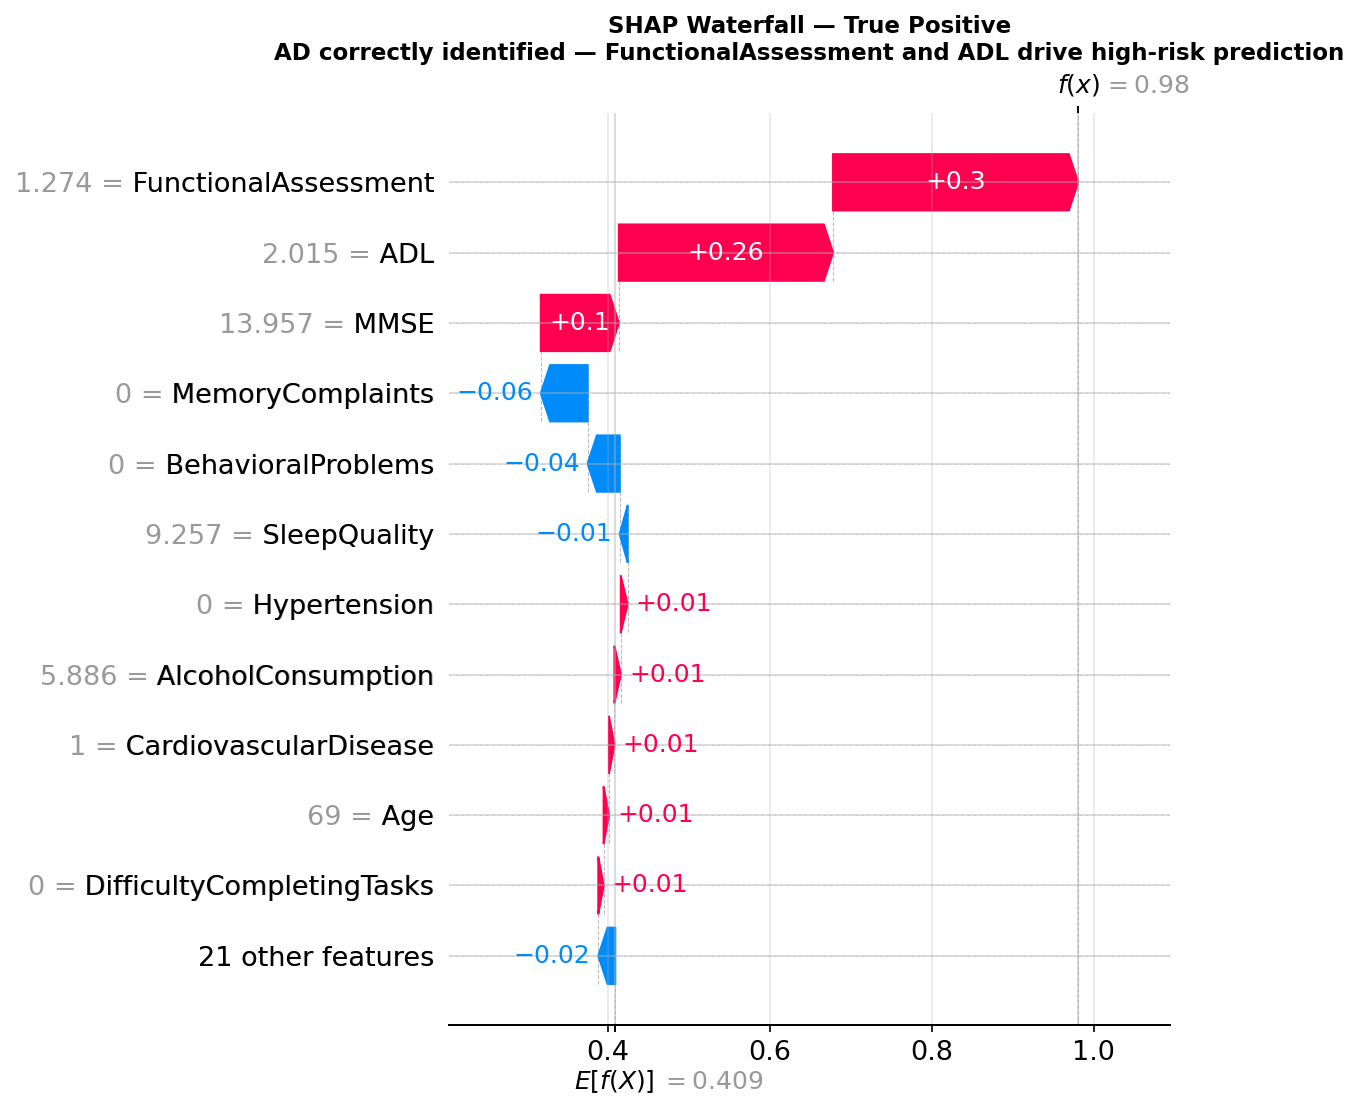

  ✓ True Positive saved


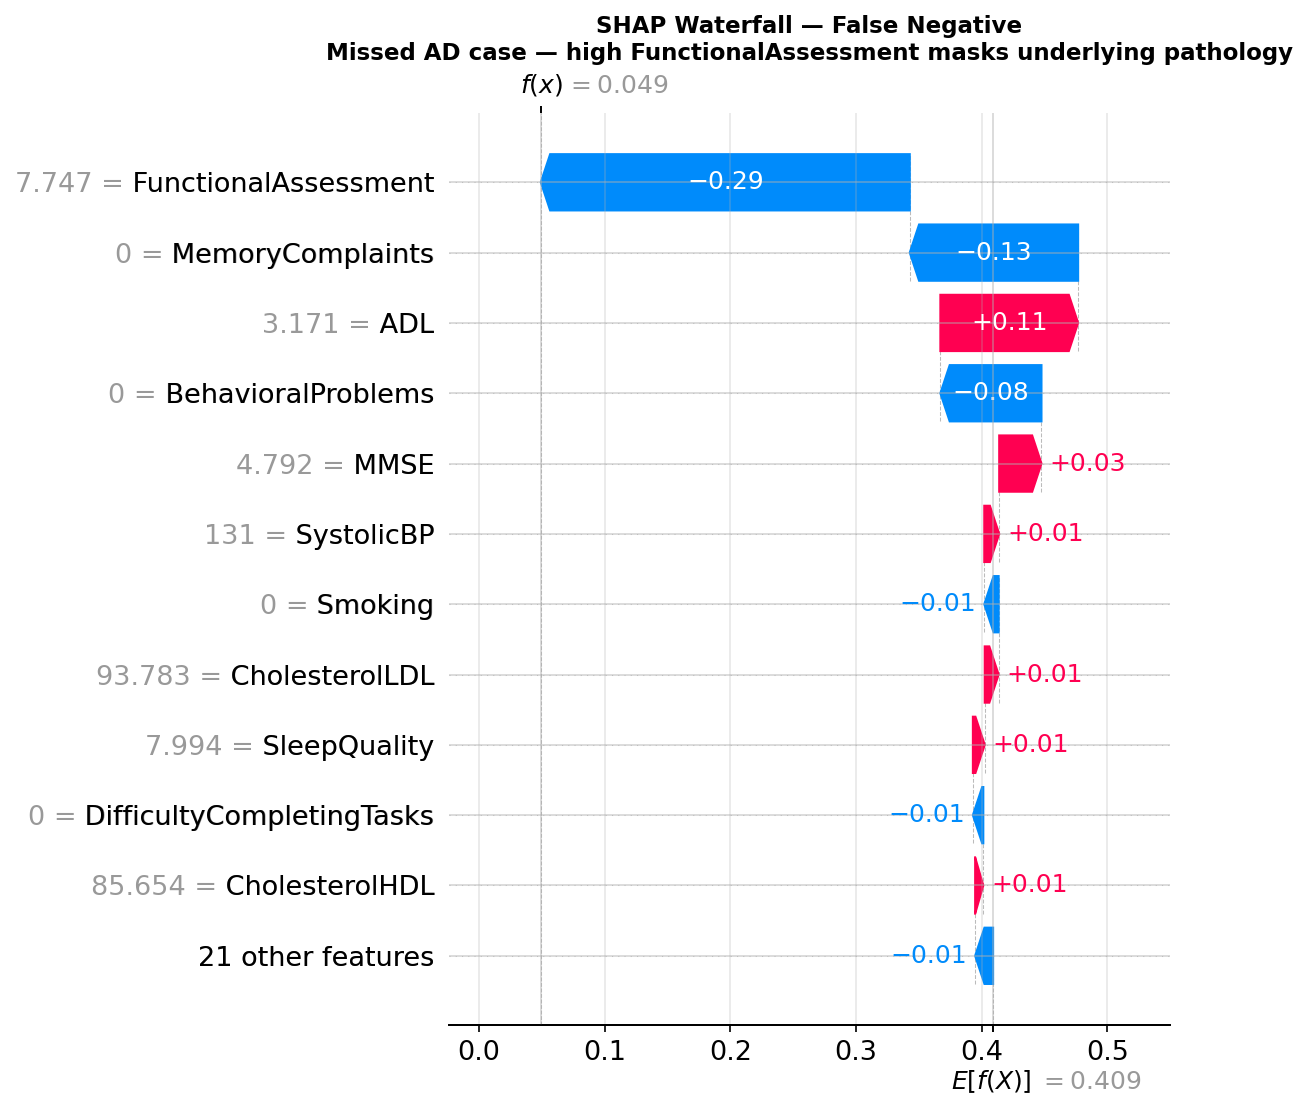

  ✓ False Negative saved


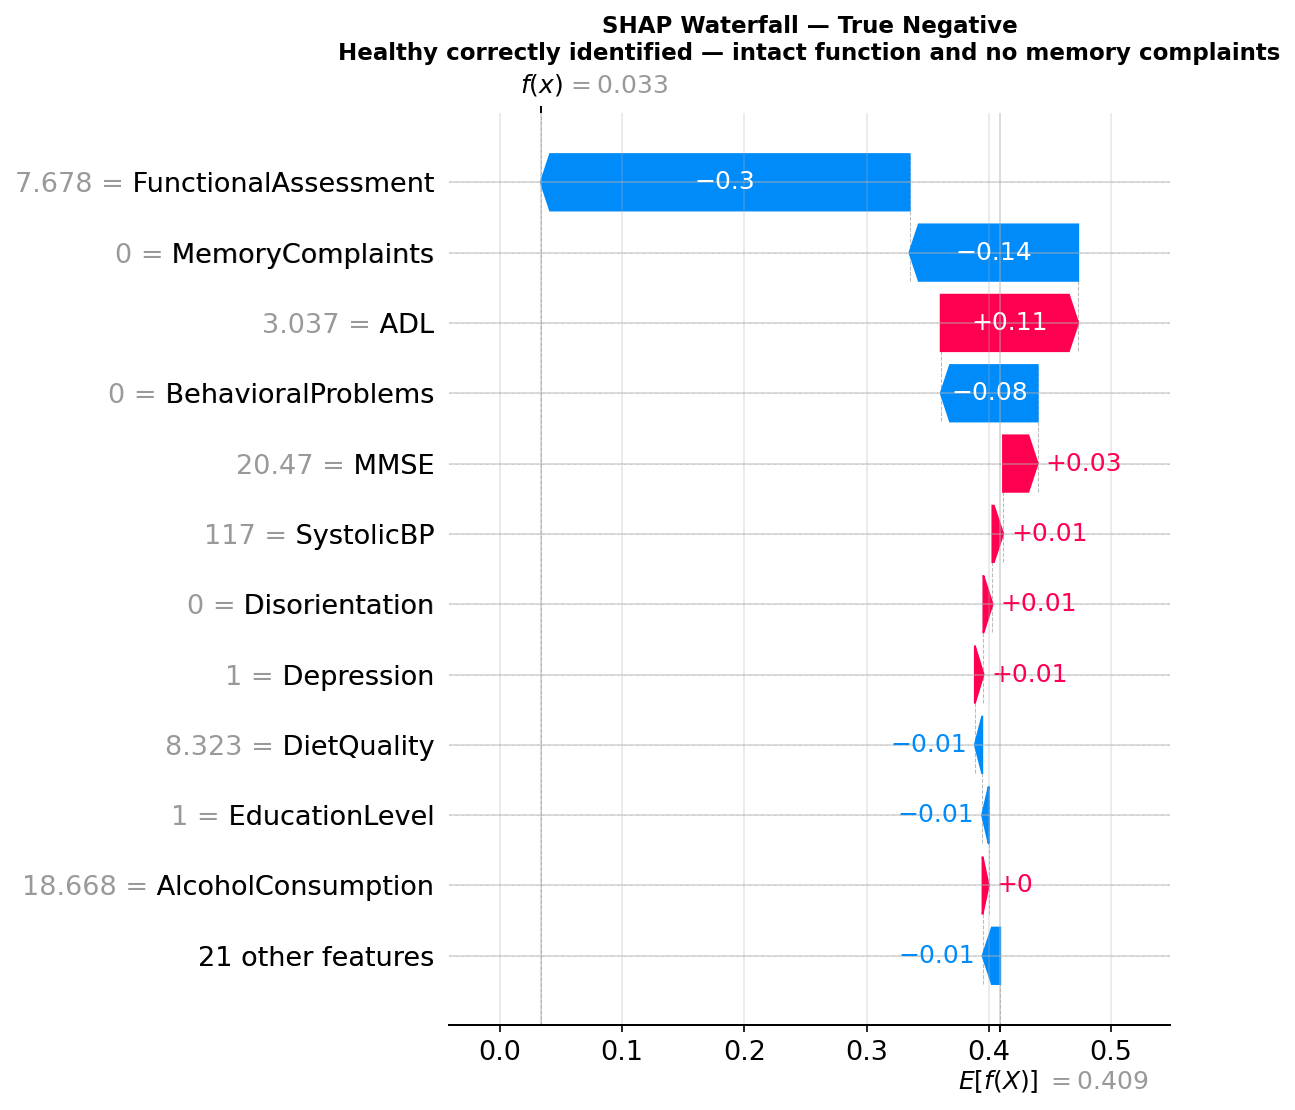

  ✓ True Negative saved


In [24]:
# ============================================================
# CELL 21 — SHAP local: Waterfall plots (TP, FN, TN)
# ============================================================
ev = explainer_ens.expected_value
base_val = float(np.atleast_1d(ev)[0])

exp = shap.Explanation(
    values=sv,
    base_values=np.full(len(sv), base_val),
    data=Xte_arr,
    feature_names=feat_names)

y_pred_ens = stack_clf.predict(X_test_imp)
y_test_arr = np.array(y_test)

for label, mask, fname, narrative in [
    ('True Positive',
     (y_pred_ens==1) & (y_test_arr==1), 'TP',
     'AD correctly identified — FunctionalAssessment and ADL drive high-risk prediction'),
    ('False Negative',
     (y_pred_ens==0) & (y_test_arr==1), 'FN',
     'Missed AD case — high FunctionalAssessment masks underlying pathology'),
    ('True Negative',
     (y_pred_ens==0) & (y_test_arr==0), 'TN',
     'Healthy correctly identified — intact function and no memory complaints'),
]:
    idx = np.where(mask)[0]
    if len(idx) == 0:
        print(f"No {label} found"); continue
    plt.figure(figsize=(11, 5))
    shap.waterfall_plot(exp[idx[0]], max_display=12, show=False)
    plt.title(f'SHAP Waterfall — {label}\n{narrative}', fontweight='bold', fontsize=11)
    plt.tight_layout()
    plt.savefig(f'outputs/10_waterfall_{fname}.png', dpi=150, bbox_inches='tight')
    plt.show()
    print(f"  ✓ {label} saved")



Top 3 features for dependence plots: ['FunctionalAssessment', 'ADL', 'MemoryComplaints']


<Figure size 1050x750 with 0 Axes>

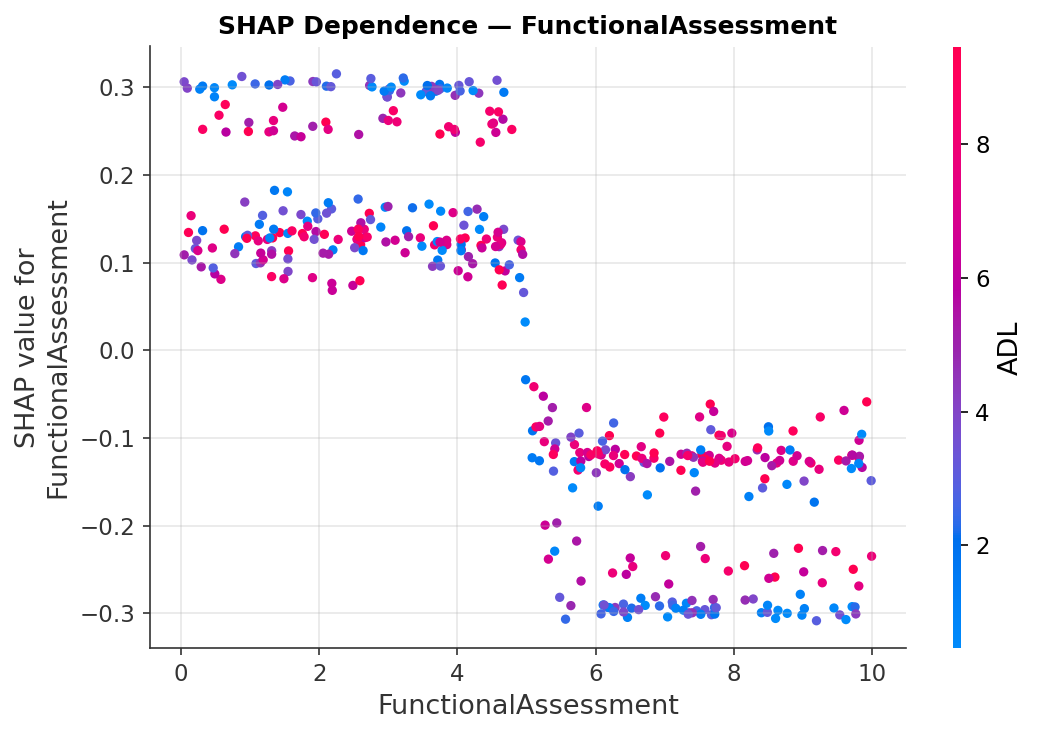

<Figure size 1050x750 with 0 Axes>

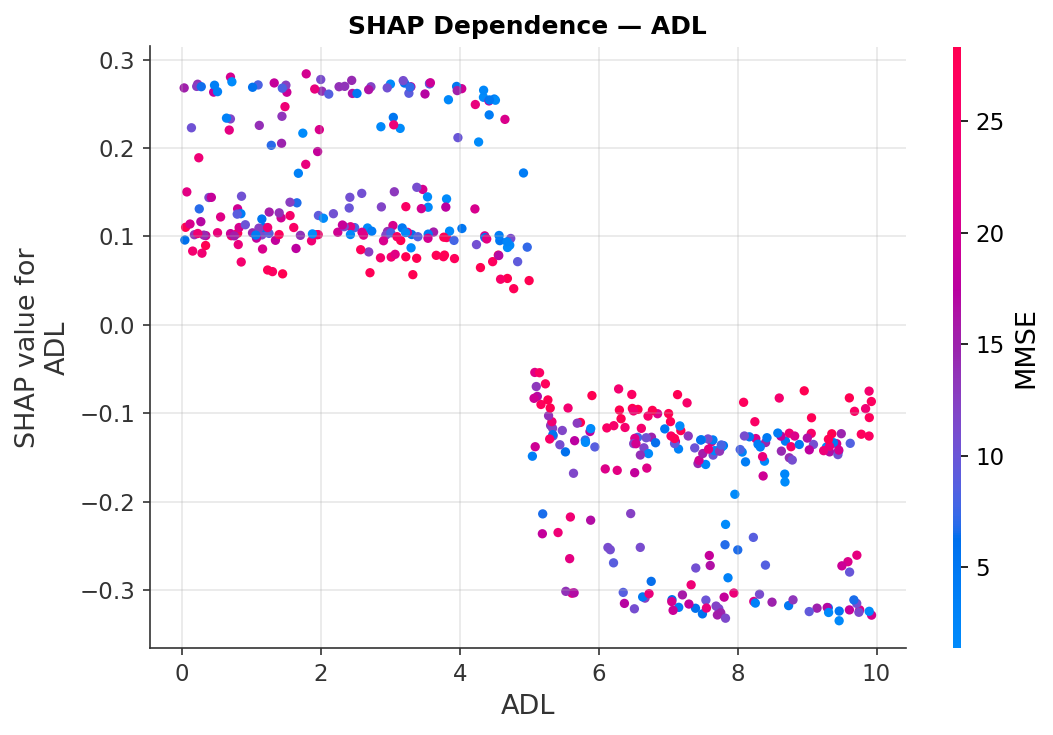

<Figure size 1050x750 with 0 Axes>

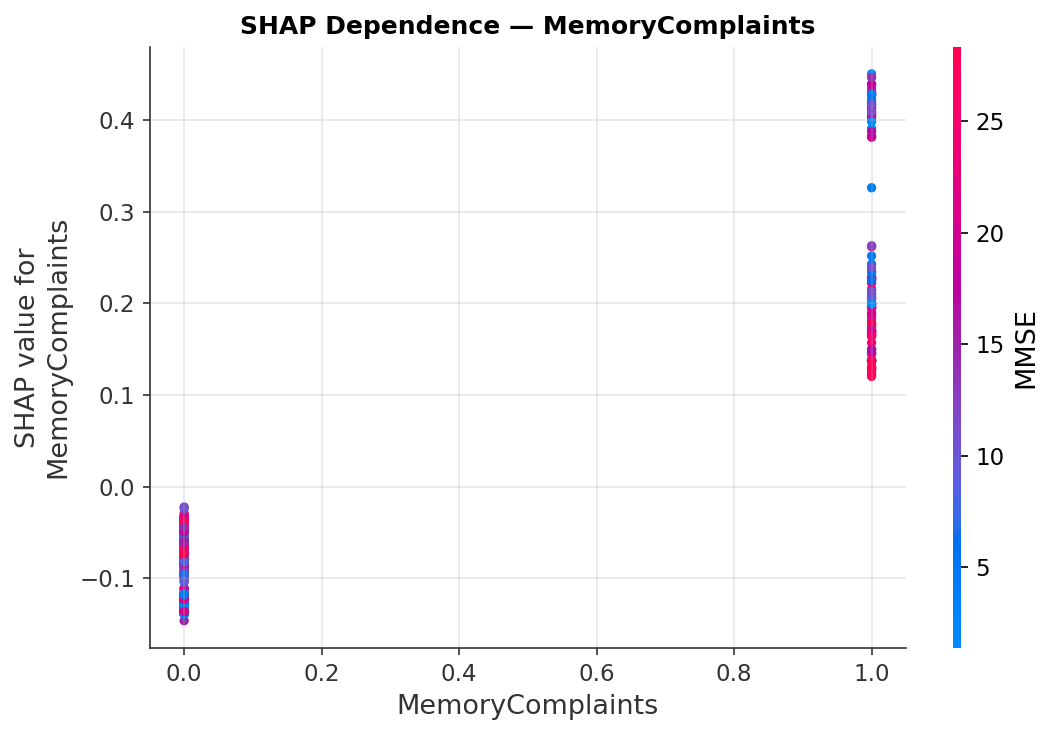

In [25]:
# ============================================================
# CELL 22 — SHAP dependence plots (top 3 features)
# ============================================================
top3 = shap_imp.head(3).index.tolist()
print(f"Top 3 features for dependence plots: {top3}")

for feat in top3:
    if feat not in feat_names: continue
    feat_idx = feat_names.index(feat)
    plt.figure(figsize=(7, 5))
    shap.dependence_plot(feat_idx, sv, Xte_arr,
                         feature_names=feat_names, show=False, dot_size=20)
    plt.title(f'SHAP Dependence — {feat}', fontweight='bold', fontsize=12)
    plt.tight_layout()
    plt.savefig(f'outputs/11_dependence_{feat}.png', dpi=150, bbox_inches='tight')
    plt.show()



In [26]:
# ============================================================
# CELL 23 — Summary tables (publication-ready)
# ============================================================

print("\n" + "="*70)
print("TABLE 1: Individual Model Performance on Held-Out Test Set")
print("="*70)
print(pd.DataFrame(results).T.round(4).to_string())

print("\n" + "="*70)
print("TABLE 2: 5-Fold Stratified Cross-Validation (Mean ± Std)")
print("="*70)
print(cv_df.to_string())

print("\n" + "="*70)
print("TABLE 3: Ablation Study")
print("="*70)
print(abl_df.to_string())

print("\n" + "="*70)
print("TABLE 4: SHAP Biomarker Ranking (Top 15)")
print("="*70)

CLINICAL_NOTES = {
    'FunctionalAssessment': 'Objective task performance; impairment is a DSM-5 diagnostic criterion for dementia',
    'ADL': 'Daily living independence; decline reflects cortical neurodegeneration severity',
    'MemoryComplaints': 'Subjective complaint preceding objective cognitive decline; early screening signal',
    'MMSE': 'Primary cognitive screening instrument; directly measures orientation and memory',
    'BehavioralProblems': 'Neuropsychiatric symptoms reflecting frontal-limbic involvement in AD',
    'SleepQuality': 'Poor sleep impairs glymphatic amyloid-β clearance during slow-wave sleep',
    'FamilyHistoryAlzheimers': 'First-degree family history doubles AD risk via shared genetic loading',
    'Gender': 'Female sex associated with higher AD incidence potentially via hormonal and longevity factors',
    'CholesterolTriglycerides': 'Elevated triglycerides linked to vascular contributions to cognitive impairment',
    'CholesterolHDL': 'Low HDL associated with increased cerebral amyloid burden',
    'DiastolicBP': 'Midlife diastolic hypertension a robust predictor of late-life dementia',
    'Age': 'Primary non-modifiable risk factor; AD prevalence doubles every 5 years after 65',
    'PhysicalActivity': 'Modifiable protective factor; aerobic exercise promotes BDNF and reduces amyloid',
    'CardiovascularDisease': 'Shared vascular pathology with AD via cerebral hypoperfusion',
    'EducationLevel': 'Cognitive reserve hypothesis; higher education delays clinical AD symptom onset',
}

bio_rows = []
for feat, imp_val in shap_imp.head(15).items():
    bio_rows.append({
        'Rank': len(bio_rows) + 1,
        'Feature': feat,
        'Mean |SHAP|': round(imp_val, 5),
        'Clinical Interpretation': CLINICAL_NOTES.get(feat, 'Associated with AD risk in this dataset')
    })
bio_df = pd.DataFrame(bio_rows)
print(bio_df.to_string(index=False))

# Save all tables
results_df.round(4).to_csv('outputs/table1_model_comparison.csv')
cv_df.to_csv('outputs/table2_crossval.csv')
abl_df.to_csv('outputs/table3_ablation.csv')
bio_df.to_csv('outputs/table4_biomarker_ranking.csv', index=False)

print("\n" + "="*70)
print("✓ ALL OUTPUTS SAVED TO /outputs/")
print("="*70)
print("\nFiles generated:")
for f in sorted(os.listdir('outputs')):
    print(f"  outputs/{f}")


TABLE 1: Individual Model Performance on Held-Out Test Set
                     Accuracy  Precision  Recall      F1     AUC     MCC
Logistic Regression    0.8163     0.6952  0.8553  0.8196  0.8865  0.6270
Random Forest          0.9465     0.9329  0.9145  0.9464  0.9419  0.8826
XGBoost                0.9488     0.9452  0.9079  0.9486  0.9480  0.8875
LightGBM               0.9488     0.9392  0.9145  0.9487  0.9503  0.8876
CatBoost               0.9465     0.9272  0.9211  0.9465  0.9414  0.8828
SVM (RBF)              0.8535     0.7834  0.8092  0.8540  0.8972  0.6820
MLP                    0.7977     0.7152  0.7105  0.7975  0.8653  0.5567
Stacking Ensemble      0.9512     0.9396  0.9211  0.9511  0.9429  0.8928

TABLE 2: 5-Fold Stratified Cross-Validation (Mean ± Std)
                      AUC μ   AUC σ    F1 μ    F1 σ   MCC μ   MCC σ
Logistic Regression  0.9146  0.0118  0.8423  0.0124  0.6865  0.0235
Random Forest        0.9727  0.0092  0.9527  0.0117  0.9066  0.0229
XGBoost              